# **Project Name** - Customer Satisfaction (CSAT) Prediction using Deep Learning (ANN)



##### **Project Type** - Supervised Machine Learning / Deep Learning
##### **Contribution** - Individual
##### **Platform** - Shopzilla E-Commerce Support Operations  
##### **Target Variable:** `CSAT Score` (Customer Rating: 1 to 5)  
##### **Model Architecture:** Deep Artificial Neural Network

# **Project Summary**

This project explores prediction of ordinal **CSAT ratings (1–5)** from customer-support records using an ANN. The dataset contains **85,907 labeled interactions** across **Inbound, Outcall and Email** channels.

EDA shows that score **5 accounts for 69.4%** of tickets and score **1 for 13.1%**. Observed numerical coverage is limited: **17,206 prices**, **242 handling times**, and **104 tickets with both**. The analysis preserves those observed values separately from model imputations so descriptive plots reflect measured data.

The intended application is to help identify interactions that may need service recovery. This dataset contains rated interactions only, so it cannot establish the platform-wide survey response rate or prove performance on unrated tickets. Prediction-time feature availability and held-out evaluation are required before deployment.

# **Github Link**

https://github.com/saiabhiram-simhadri/ecommerce-customer-csat-score-prediction

# **Problem Statement**


Shopzilla's customer support operations currently run in a reactive mode. Service breakdowns, mishandled interactions, and logistics delays are typically flagged only after a low survey score is logged or after an unhappy shopper defects to another platform.

Workloads and resolution times also vary considerably across agent experience levels and operating shifts, leading to inconsistent response speeds and resolution quality. Management requires an automated prediction system that forecasts a 1-to-5 CSAT score for every incoming customer support interaction. Real-time predictions enable supervisors to triage low-satisfaction tickets immediately, initiate service recovery workflows (such as priority follow-ups or concession vouchers), and address customer friction before it leads to churn.

# **Analysis and Modeling**

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# Import Libraries

import os
import re
import sys
import json
import random
import warnings
import joblib

# Numerical Operations & Data Structures
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

# Statistical Hypothesis Testing & Distributions
from scipy import stats

# Data Visualization & Plotting Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn: Dataset Splitting, Preprocessing & Feature Extraction
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.utils.class_weight import compute_class_weight

# Scikit-Learn: Classification & Ordinal Metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

# TensorFlow is imported in the model section so EDA can run independently.

# High-DPI Retina inline display
%config InlineBackend.figure_format = 'retina'

# Custom Eye-Friendly Dark Theme Palette
CUSTOM_THEME = {
    'bg':       '#18191C',  # Soft Dark Slate Gray
    'card':     '#222428',  # Elevated Surface Card
    'grid':     '#32363C',  # Low-Contrast Grid Lines
    'text':     '#E3E5E8',  # Warm Off-White
    'subtext':  '#9B9D9E',  # Muted Axis Label Grey
    'teal':     '#2DD4BF',  # Soft Mint Teal
    'coral':    '#F87171',  # Soft Crimson Coral
    'purple':   '#A78BFA',  # Soft Lavender Purple
    'orange':   '#FB923C',  # Soft Warm Orange
}

# Apply global parameters
plt.rcParams.update({
    'figure.facecolor':  CUSTOM_THEME['bg'],
    'axes.facecolor':    CUSTOM_THEME['card'],
    'savefig.facecolor': CUSTOM_THEME['bg'],
    'axes.edgecolor':    CUSTOM_THEME['grid'],
    'axes.labelcolor':   CUSTOM_THEME['text'],
    'xtick.color':       CUSTOM_THEME['subtext'],
    'ytick.color':       CUSTOM_THEME['subtext'],
    'grid.color':        CUSTOM_THEME['grid'],
    'grid.linestyle':    '--',
    'grid.alpha':        0.6,
    'text.color':        CUSTOM_THEME['text'],
    'axes.titlepad':     12,
    'axes.labelpad':     8,
    'legend.facecolor': CUSTOM_THEME['card'],
    'legend.labelcolor': CUSTOM_THEME['text'],
})

# Global Seed Setup
SEED = 47
random.seed(SEED)
np.random.seed(SEED)


print(f"Global Random Seed Initialized to : {SEED}")
print('All librarires imported successfully!')

Global Random Seed Initialized to : 47
All librarires imported successfully!


In [ ]:
import textwrap

def custom_display(
    title: str | None = None,
    content: str | list[str] | None = None,
    max_width: int = 70,
    padding: int = 2
):
    """
    Renders structured text inside a Unicode box.
    - Centers the title/header if the content width spans wider.
    - Supports (title, content), (content), or (title) dynamically.
    - Honors explicit '\n' line breaks and wraps unbroken lines exceeding max_width.
    """
    pad_space = " " * padding

    # Handle single positional argument intended as content
    if content is None and title is not None and ('\n' in title or len(title) > max_width):
        content = title
        title = None

    # Parse and wrap content lines
    formatted_lines = []
    if content is not None:
        if isinstance(content, str):
            raw_sections = content.split('\n')
        else:
            raw_sections = [line for item in content for line in str(item).split('\n')]

        for section in raw_sections:
            stripped = section.strip()
            if not stripped:
                formatted_lines.append("")
            elif len(section) > max_width:
                formatted_lines.extend(textwrap.wrap(section, width=max_width))
            else:
                formatted_lines.append(section)

    title_str = title.strip() if title else ""
    has_title = bool(title_str)
    has_content = bool(formatted_lines)

    if not has_title and not has_content:
        return

    # Calculate max width across both title and content
    max_content_len = max([len(line) for line in formatted_lines]) if has_content else 0
    max_line_len = max(len(title_str) if has_title else 0, max_content_len)

    inner_width = max_line_len + (padding * 2)

    # Render Box
    print(f"┌{'─' * inner_width}┐")
    if has_title:
        # Centers the header text across the total inner width
        print(f"│{title_str.center(inner_width)}│")
        if has_content:
            print(f"├{'─' * inner_width}┤")

    if has_content:
        for line in formatted_lines:
            print(f"│{pad_space}{line.ljust(max_line_len)}{pad_space}│")

    print(f"└{'─' * inner_width}┘")

### Dataset Loading

In [ ]:
# Load data from direct Google Drive shared CSV URLs
CSV_FILE_ID = "196N5zjPPbumZGNiNoB2oDMkWGj78-re5"
csv_export_url = "https://drive.google.com/uc?export=download&id={}"

cust_support_df = pd.read_csv(csv_export_url.format(CSV_FILE_ID))

### Dataset First View

In [ ]:
# Dataset First Look
cust_support_df.head()

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count
total_rows, total_cols = cust_support_df.shape
custom_display(content=[
    f"Dataset Rows    : {cust_support_df.shape[0]}",
    f"Dataset Columns : {cust_support_df.shape[1]}",
])

┌───────────────────────────┐
│  Dataset Rows    : 85907  │
│  Dataset Columns : 20     │
└───────────────────────────┘


### Dataset Information

In [ ]:
# Dataset Info

# Structural schema and memory footprint
print("--- Dataset Information & Data Types ---")
cust_support_df.info()

# Statistical Summary - Numerical Features
print("\n--- Numerical Attributes Summary ---")
display(cust_support_df.describe().T)

# Statistical Summary - Categorical Features
print("\n--- Categorical Attributes Summary ---")
display(cust_support_df.describe(include=['O']).T)

--- Dataset Information & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  object 
 1   channel_name             85907 non-null  object 
 2   category                 85907 non-null  object 
 3   Sub-category             85907 non-null  object 
 4   Customer Remarks         28742 non-null  object 
 5   Order_id                 67675 non-null  object 
 6   order_date_time          17214 non-null  object 
 7   Issue_reported at        85907 non-null  object 
 8   issue_responded          85907 non-null  object 
 9   Survey_response_Date     85907 non-null  object 
 10  Customer_City            17079 non-null  object 
 11  Product_category         17196 non-null  object 
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-nu

,count,mean,std,min,25%,50%,75%,max
Item_price,17206.0,5660.774846,12825.728411,0.0,392.0,979.0,2699.75,164999.0
connected_handling_time,242.0,462.400826,246.295037,0.0,293.0,427.0,592.25,1986.0
CSAT Score,85907.0,4.242157,1.378903,1.0,4.0,5.0,5.00,5.0



--- Categorical Attributes Summary ---


,count,unique,top,freq
Unique id,85907,85907,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,1
channel_name,85907,3,Inbound,68142
category,85907,12,Returns,44097
Sub-category,85907,57,Reverse Pickup Enquiry,22389
Customer Remarks,28742,18231,Good,1390
Order_id,67675,67675,c27c9bb4-fa36-4140-9f1f-21009254ffdb,1
order_date_time,17214,13766,09/08/2023 11:55,7
Issue_reported at,85907,30923,13/08/2023 10:40,13
issue_responded,85907,30262,28/08/2023 00:00,3378
Survey_response_Date,85907,31,28-Aug-23,3452


#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
duplicate_rows = cust_support_df.duplicated().sum()
custom_display(f"Duplicate Rows Detected across all columns: {duplicate_rows}")

┌─────────────────────────────────────────────────┐
│  Duplicate Rows Detected across all columns: 0  │
└─────────────────────────────────────────────────┘


#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count
null_counts = cust_support_df.isnull().sum()
null_percent = (cust_support_df.isnull().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Data Type': cust_support_df.dtypes,
    'Non-Null Count': cust_support_df.notnull().sum(),
    'Null Count': null_counts,
    'Null Percentage (%)': null_percent,
    'Unique Count': cust_support_df.nunique()
})
display(missing_df)

,Data Type,Non-Null Count,Null Count,Null Percentage (%),Unique Count
Unique id,object,85907,0,0.00,85907
channel_name,object,85907,0,0.00,3
category,object,85907,0,0.00,12
Sub-category,object,85907,0,0.00,57
Customer Remarks,object,28742,57165,66.54,18231
Order_id,object,67675,18232,21.22,67675
order_date_time,object,17214,68693,79.96,13766
Issue_reported at,object,85907,0,0.00,30923
issue_responded,object,85907,0,0.00,30262
Survey_response_Date,object,85907,0,0.00,31


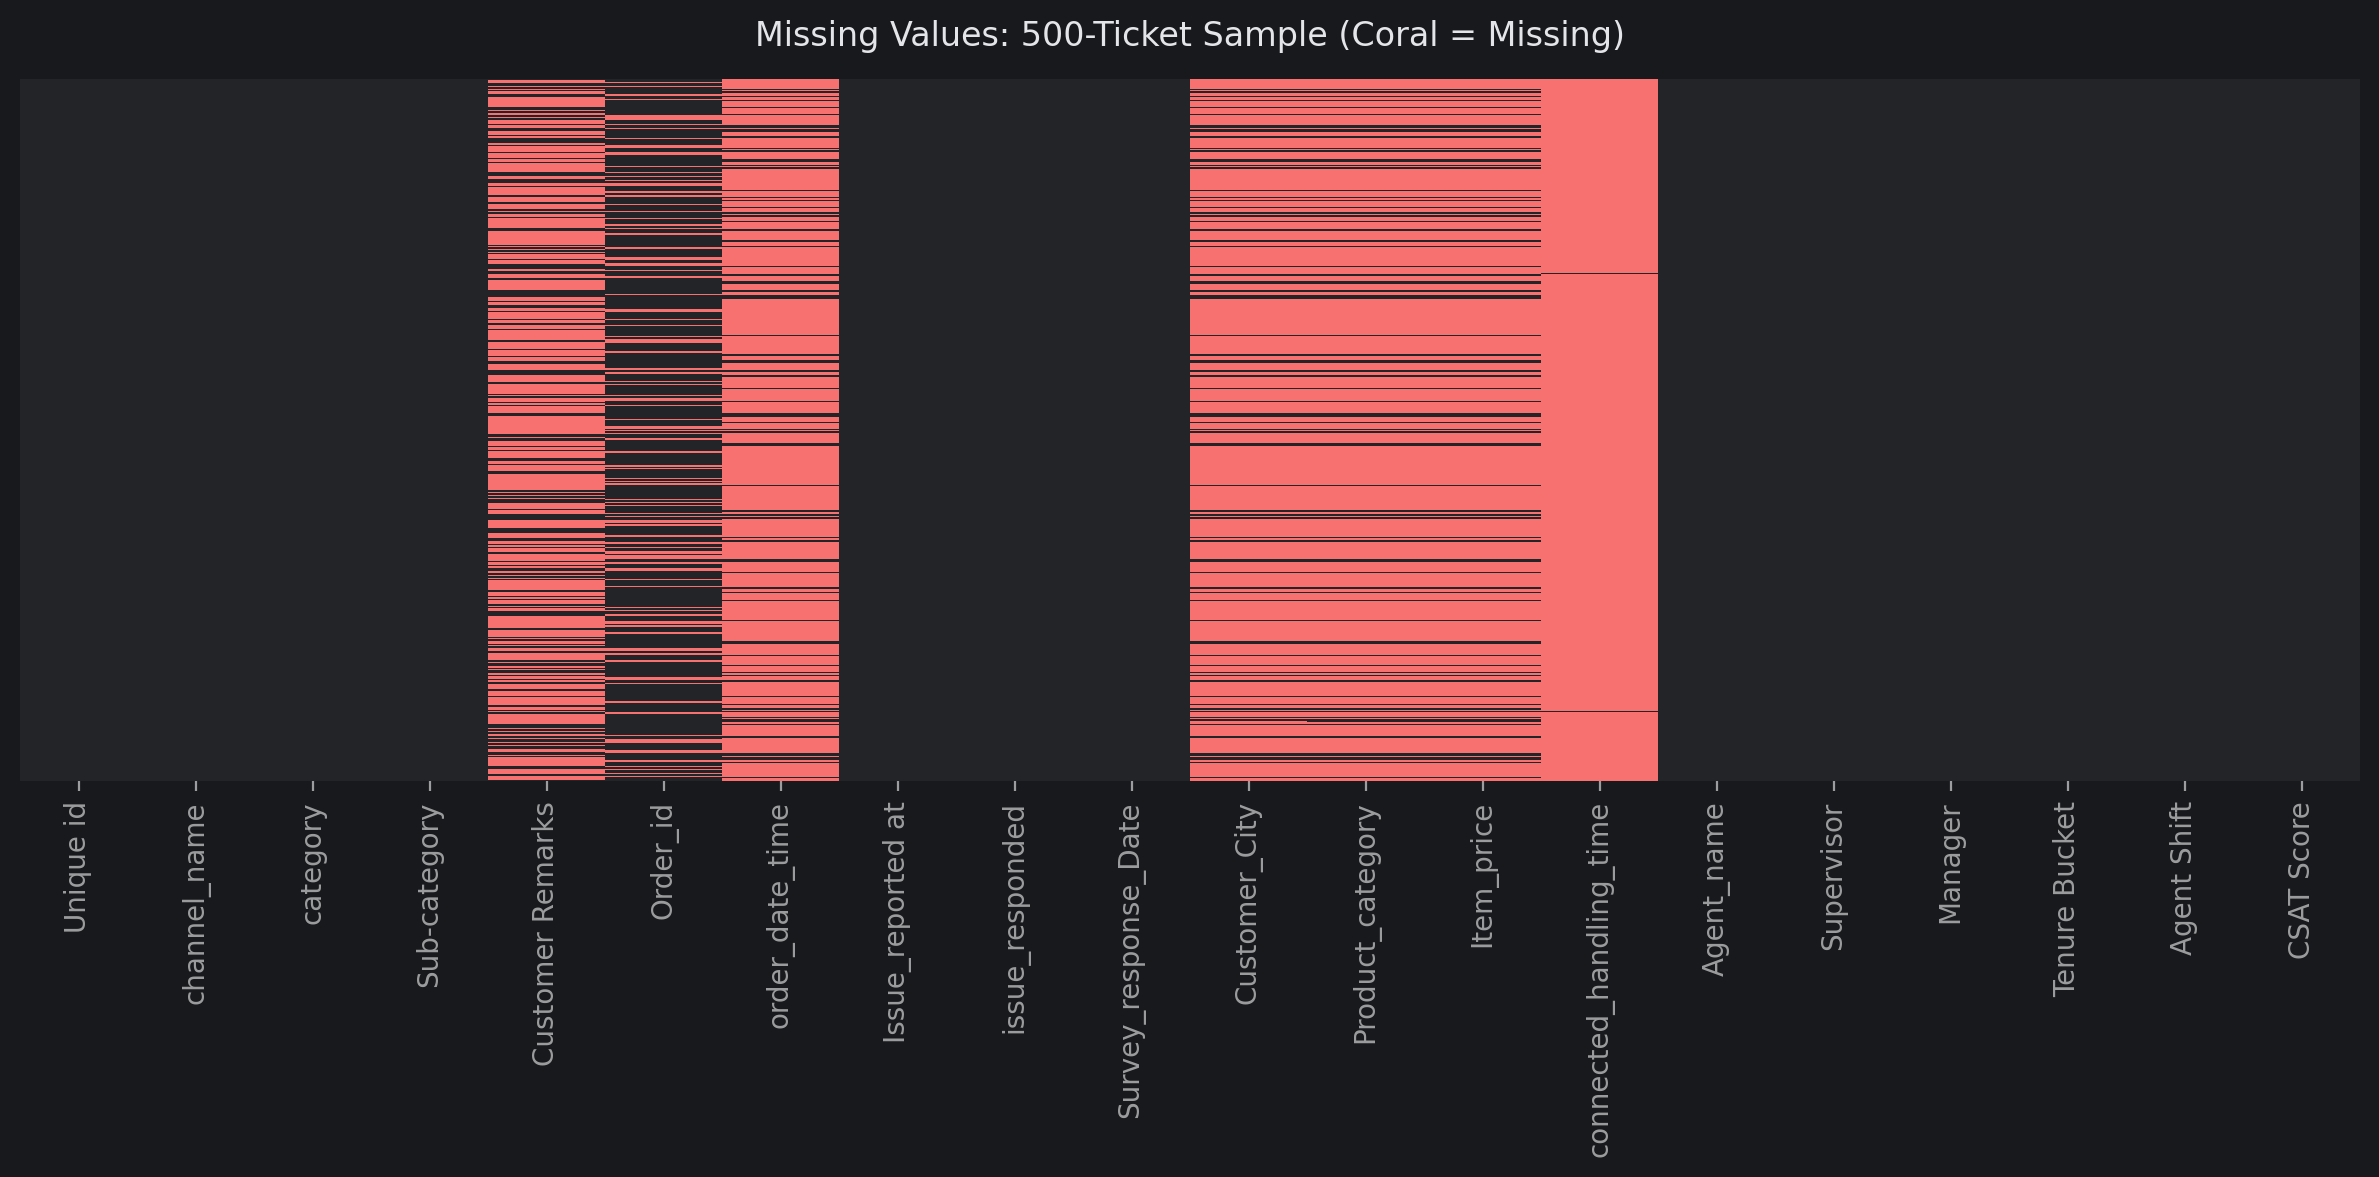

In [ ]:
# Missing-value patterns in a representative sample.
missing_sample = cust_support_df.sample(n=min(500, len(cust_support_df)), random_state=SEED)

plt.figure(figsize=(12, 6))
sns.heatmap(missing_sample.isna(), cmap=[CUSTOM_THEME['card'], CUSTOM_THEME['coral']],
            cbar=False, yticklabels=False)
plt.title('Missing Values: 500-Ticket Sample (Coral = Missing)')
plt.tight_layout()
plt.show()

### What did you know about your dataset?

* **Scale:** 85,907 records and 20 original attributes; wrangling retains 85,907 rows.
* **Target:** CSAT 5 accounts for 59,617 tickets (69.4%); CSAT 1 for 11,230 (13.1%). Ratings 2 and 3 are particularly sparse.
* **Observed numerical coverage:** Item price is available for 17,206 tickets (20.0%); handling time for 242 (0.28%). Only 104 tickets have both. EDA excludes missing measurements rather than treating imputed medians as observations.
* **Feedback:** 57,165 remarks are missing (66.5%). Missing order context may reflect different ticket types, but its cause is not established by missingness alone.
* **Metadata:** Timestamps, support channel, issue category, shift and tenure enable descriptive comparisons. The data contains Email, Inbound and Outcall channels.

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
list(cust_support_df.columns)

['Unique id',
 'channel_name',
 'category',
 'Sub-category',
 'Customer Remarks',
 'Order_id',
 'order_date_time',
 'Issue_reported at',
 'issue_responded',
 'Survey_response_Date',
 'Customer_City',
 'Product_category',
 'Item_price',
 'connected_handling_time',
 'Agent_name',
 'Supervisor',
 'Manager',
 'Tenure Bucket',
 'Agent Shift',
 'CSAT Score']

In [ ]:
# Dataset Describe
print("--- Numerical Attributes Summary ---")
display(cust_support_df.describe().T)

# Statistical summary for categorical and text features
print("\n--- Categorical & Text Attributes Summary ---")
display(cust_support_df.describe(include=['O']).T)

--- Numerical Attributes Summary ---


,count,mean,std,min,25%,50%,75%,max
Item_price,17206.0,5660.774846,12825.728411,0.0,392.0,979.0,2699.75,164999.0
connected_handling_time,242.0,462.400826,246.295037,0.0,293.0,427.0,592.25,1986.0
CSAT Score,85907.0,4.242157,1.378903,1.0,4.0,5.0,5.00,5.0



--- Categorical & Text Attributes Summary ---


,count,unique,top,freq
Unique id,85907,85907,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,1
channel_name,85907,3,Inbound,68142
category,85907,12,Returns,44097
Sub-category,85907,57,Reverse Pickup Enquiry,22389
Customer Remarks,28742,18231,Good,1390
Order_id,67675,67675,c27c9bb4-fa36-4140-9f1f-21009254ffdb,1
order_date_time,17214,13766,09/08/2023 11:55,7
Issue_reported at,85907,30923,13/08/2023 10:40,13
issue_responded,85907,30262,28/08/2023 00:00,3378
Survey_response_Date,85907,31,28-Aug-23,3452


### Variables Description

* **Unique id (String / Alphanumeric):** Unique identifier assigned to track each individual customer support ticket or interaction.
* **channel_name (String / Categorical):** Support channel through which the interaction took place, such as Inbound call, Outcall, or Email.
* **category (String / Categorical):** High-level functional category of the customer request (e.g., Returns, Order Related, Cancellation, Product Queries).
* **Sub-category (String / Categorical):** Specific issue or granular service topic under the main category (e.g., Reverse Pickup Enquiry, Installation/demo, Delayed).
* **Customer Remarks (String / Text):** Free-form qualitative feedback and comments provided by the customer regarding their service experience.
* **Order_id (String / Alphanumeric):** Unique order identifier associated with the support ticket (missing for some tickets; the reason is not established).
* **order_date_time (Datetime / String):** Exact date and timestamp when the customer originally placed the purchase order.
* **Issue_reported at (Datetime / String):** Timestamp when the customer first reported the issue or contacted customer support.
* **issue_responded (Datetime / String):** Timestamp when a customer support representative responded to or handled the inquiry.
* **Survey_response_Date (Datetime / String):** Date when the customer submitted their feedback rating and survey response.
* **Customer_City (String / Categorical):** Registered delivery city or geographic location of the customer.
* **Product_category (String / Categorical):** Merchandise department or product classification of the purchased item (e.g., Electronics, LifeStyle, Mobile).
* **Item_price (Float / Continuous):** Purchase monetary value associated with the ticket; currency is not documented in the CSV.
* **connected_handling_time (Float / Continuous):** Duration taken by the agent to handle the customer interaction, reported in source units; the CSV does not document the duration unit.
* **Agent_name (String / Categorical):** Name of the customer service representative who handled the interaction.
* **Supervisor (String / Categorical):** Direct team lead or supervisor overseeing the handling agent.
* **Manager (String / Categorical):** Support operations manager responsible for the respective support unit.
* **Tenure Bucket (String / Categorical):** Experience band of the handling agent (e.g., On Job Training, 0-30, 31-60, 61-90, >90 days).
* **Agent Shift (String / Categorical):** Operational working shift during which the interaction occurred (Morning, Afternoon, Evening, Night, Split).
* **CSAT Score (Integer / Ordinal):** Customer Satisfaction score given by the customer on a discrete 1-to-5 scale, serving as the primary multi-class target variable.

### Check Unique Values for each variable.

In [ ]:
# Tabular overview of unique value counts across all attributes
print("--- UNIQUE VALUE COUNTS PER ATTRIBUTE ---")
unique_profile = pd.DataFrame({
    'Data Type': cust_support_df.dtypes,
    'Unique Values': cust_support_df.nunique()
})
display(unique_profile)

# Detailed value counts for categorical support and workforce attributes
print("\n--- CATEGORICAL ATTRIBUTES VALUE DISTRIBUTIONS ---")

categorical_cols = [
    'channel_name',
    'category',
    'Tenure Bucket',
    'Agent Shift',
    'Product_category',
    'CSAT Score'
]

for col in categorical_cols:
    if col in cust_support_df.columns:
        print(f"\n--- Distribution for [{col}] ---")
        display(cust_support_df[col].value_counts(dropna=False))

--- UNIQUE VALUE COUNTS PER ATTRIBUTE ---


,Data Type,Unique Values
Unique id,object,85907
channel_name,object,3
category,object,12
Sub-category,object,57
Customer Remarks,object,18231
Order_id,object,67675
order_date_time,object,13766
Issue_reported at,object,30923
issue_responded,object,30262
Survey_response_Date,object,31



--- CATEGORICAL ATTRIBUTES VALUE DISTRIBUTIONS ---

--- Distribution for [channel_name] ---


,count
channel_name,
Inbound,68142
Outcall,14742
Email,3023



--- Distribution for [category] ---


,count
category,
Returns,44097
Order Related,23215
Refund Related,4550
Product Queries,3692
Shopzilla Related,2792
Payments related,2327
Feedback,2294
Cancellation,2212
Offers & Cashback,480


... (4 outputs left out)


--- Distribution for [Product_category] ---


,count
Product_category,
NaN,68711
Electronics,4706
LifeStyle,4118
Books & General merchandise,3323
Mobile,1758
Home,1328
Home Appliences,1300
Furniture,471
Affiliates,166



--- Distribution for [CSAT Score] ---


,count
CSAT Score,
5,59617
1,11230
4,11219
3,2558
2,1283


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
# Write your code to make your dataset analysis ready.
# Create a dedicated working copy
df = cust_support_df.copy()

# 1. Standardize column names to clean, uniform snake_case
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('-', '_')
)

# 2. De-duplicate records based on the unique interaction identifier
initial_rows = len(df)
df = df.drop_duplicates(subset=['unique_id'])
print(f"Dropped {initial_rows - len(df)} duplicate records based on 'unique_id'.")

# 3. Parse mixed timestamp strings into pandas datetime objects
datetime_cols = [
    'order_date_time',
    'issue_reported_at',
    'issue_responded',
    'survey_response_date'
]

for col in datetime_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce', dayfirst=True, format='mixed')

# 4. Filter target variable integrity (verify valid integer scale 1 to 5)
df = df.dropna(subset=['csat_score', 'issue_reported_at'])
df['csat_score'] = df['csat_score'].astype(int)
df = df[df['csat_score'].between(1, 5)]

# 5. Handle informative missing values in text and categorical attributes
df['customer_remarks'] = df['customer_remarks'].fillna("No Remarks Provided").astype(str).str.strip()
df['customer_city'] = df['customer_city'].fillna("Unknown").astype(str).str.strip().str.upper()
df['product_category'] = df['product_category'].fillna("General / Not Specified").astype(str).str.strip()
df['channel_name'] = df['channel_name'].fillna("Inbound").astype(str).str.strip()
df['category'] = df['category'].fillna("General Enquiry").astype(str).str.strip()
df['sub_category'] = df['sub_category'].fillna("General").astype(str).str.strip()
df['tenure_bucket'] = df['tenure_bucket'].fillna("Unknown").astype(str).str.strip()
df['agent_shift'] = df['agent_shift'].fillna("General").astype(str).str.strip()

# Preserve observed measurements for EDA before numerical imputation/capping.
for col in ['item_price', 'connected_handling_time']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col] = df[col].where(np.isfinite(df[col]) & df[col].ge(0))

eda_df = df.copy(deep=True)
outlier_bounds = {}
for col in ['item_price', 'connected_handling_time']:
    observed = eda_df[col].dropna()
    q25, q75 = observed.quantile([0.25, 0.75])
    # A zero IQR is not evidence that all larger observations are invalid.
    outlier_bounds[col] = q75 + 2.5 * (q75 - q25) if q75 > q25 else np.inf

# 6. Impute continuous numerical fields using median
median_price = df['item_price'].median()
df['item_price'] = df['item_price'].fillna(median_price)

median_handling = df['connected_handling_time'].median()
df['connected_handling_time'] = df['connected_handling_time'].fillna(median_handling)

# 7. Outlier mitigation: Cap extreme handling times and item prices using IQR fences
for num_col in ['connected_handling_time', 'item_price']:
    df[num_col] = df[num_col].clip(lower=0.0, upper=outlier_bounds[num_col])

# 8. Prune non-predictive database keys to prevent overfitting and target memorization
uninformative_ids = ['unique_id', 'order_id', 'agent_name', 'supervisor', 'manager']
df = df.drop(columns=[col for col in uninformative_ids if col in df.columns])

custom_display(f"Dataset dimensions: {df.shape[0]:,} rows, {df.shape[1]} columns")
display(df.head())

Dropped 0 duplicate records based on 'unique_id'.
┌───────────────────────────────────────────────┐
│  Dataset dimensions: 85,907 rows, 15 columns  │
└───────────────────────────────────────────────┘


,channel_name,category,sub_category,customer_remarks,order_date_time,issue_reported_at,issue_responded,survey_response_date,customer_city,product_category,item_price,connected_handling_time,tenure_bucket,agent_shift,csat_score
0,Outcall,Product Queries,Life Insurance,No Remarks Provided,NaT,2023-08-01 11:13:00,2023-08-01 11:47:00,2023-08-01,UNKNOWN,General / Not Specified,979.0,427.0,On Job Training,Morning,5
1,Outcall,Product Queries,Product Specific Information,No Remarks Provided,NaT,2023-08-01 12:52:00,2023-08-01 12:54:00,2023-08-01,UNKNOWN,General / Not Specified,979.0,427.0,>90,Morning,5
2,Inbound,Order Related,Installation/demo,No Remarks Provided,NaT,2023-08-01 20:16:00,2023-08-01 20:38:00,2023-08-01,UNKNOWN,General / Not Specified,979.0,427.0,On Job Training,Evening,5
3,Inbound,Returns,Reverse Pickup Enquiry,No Remarks Provided,NaT,2023-08-01 20:56:00,2023-08-01 21:16:00,2023-08-01,UNKNOWN,General / Not Specified,979.0,427.0,>90,Evening,5
4,Inbound,Cancellation,Not Needed,No Remarks Provided,NaT,2023-08-01 10:30:00,2023-08-01 10:32:00,2023-08-01,UNKNOWN,General / Not Specified,979.0,427.0,0-30,Morning,5


### What all manipulations have you done and insights you found?

#### Manipulations executed
* Standardized column names, removed duplicate interaction IDs (0 duplicates), parsed mixed day-first timestamps, and retained valid target/timestamp rows.
* Filled missing text and categories with explicit placeholders. Missingness may be informative; its cause has not been verified.
* Preserved an independent **`eda_df` before numerical imputation or capping**. Non-numeric, non-finite or negative price/duration values are treated as missing.
* Created `df` for later preprocessing using median imputation. Calculated upper fences from observed numerical values before imputation: price **8,469.125**, handling time **1,340.375**. A zero observed IQR leaves the upper bound uncapped.
* Removed identifier/personnel columns from `df`. No EDA plot changes its numerical values.

#### Verified descriptive results
* Observed handling time: **n=242**, median **427**, mean **462.40**, maximum **1,986** in source units.
* Observed price: **n=17,206**, median **979**, mean **5,660.77**, maximum **164,999** in source units.
* Target shares are **69.4% CSAT 5** and **13.1% CSAT 1**. Numerical summaries describe observed subsets; target and category summaries describe all 85,907 retained tickets.

## ***4. Visual Storytelling & Exploratory Data Analysis***


The 15 charts use `eda_df`, which contains **85,907 tickets**. Numerical plots use recorded values before filling missing data or capping outliers.

Satisfaction groups are **Dissatisfied (1–2)**, **Neutral (3)** and **Satisfied (4–5)**. There are **17,206 recorded prices**, **242 handling times** and **104 tickets with both measurements**. The price histogram uses log1p to make the long tail easier to see. Both CSAT heatmaps use the same **3.8–4.6** color range. Sample counts are shown in supporting tables or panel titles.


In [ ]:
# Common groups and colors used throughout EDA.
cohort_order = ['Dissatisfied (1-2)', 'Neutral (3)', 'Satisfied (4-5)']
cohort_palette = dict(zip(cohort_order, [CUSTOM_THEME['coral'], CUSTOM_THEME['orange'], CUSTOM_THEME['teal']]))
eda_df['satisfaction_cohort'] = pd.cut(eda_df['csat_score'], [0, 2, 3, 5], labels=cohort_order)
tenure_order = ['On Job Training', '0-30', '31-60', '61-90', '>90']
tenure_order += sorted(set(eda_df['tenure_bucket']) - set(tenure_order))
top_cats = eda_df['category'].value_counts().head(6).index
overall_mean = eda_df['csat_score'].mean()

rating_palette = [CUSTOM_THEME['coral'], CUSTOM_THEME['orange'], CUSTOM_THEME['purple'], CUSTOM_THEME['teal'], CUSTOM_THEME['teal']]


### Univariate Analysis (Charts 1 – 5)
Examining single-variable distributions, class skewness, and baseline central tendencies in isolation.

#### Chart - 1: Target Variable Distribution - Customer Satisfaction (CSAT) Scores

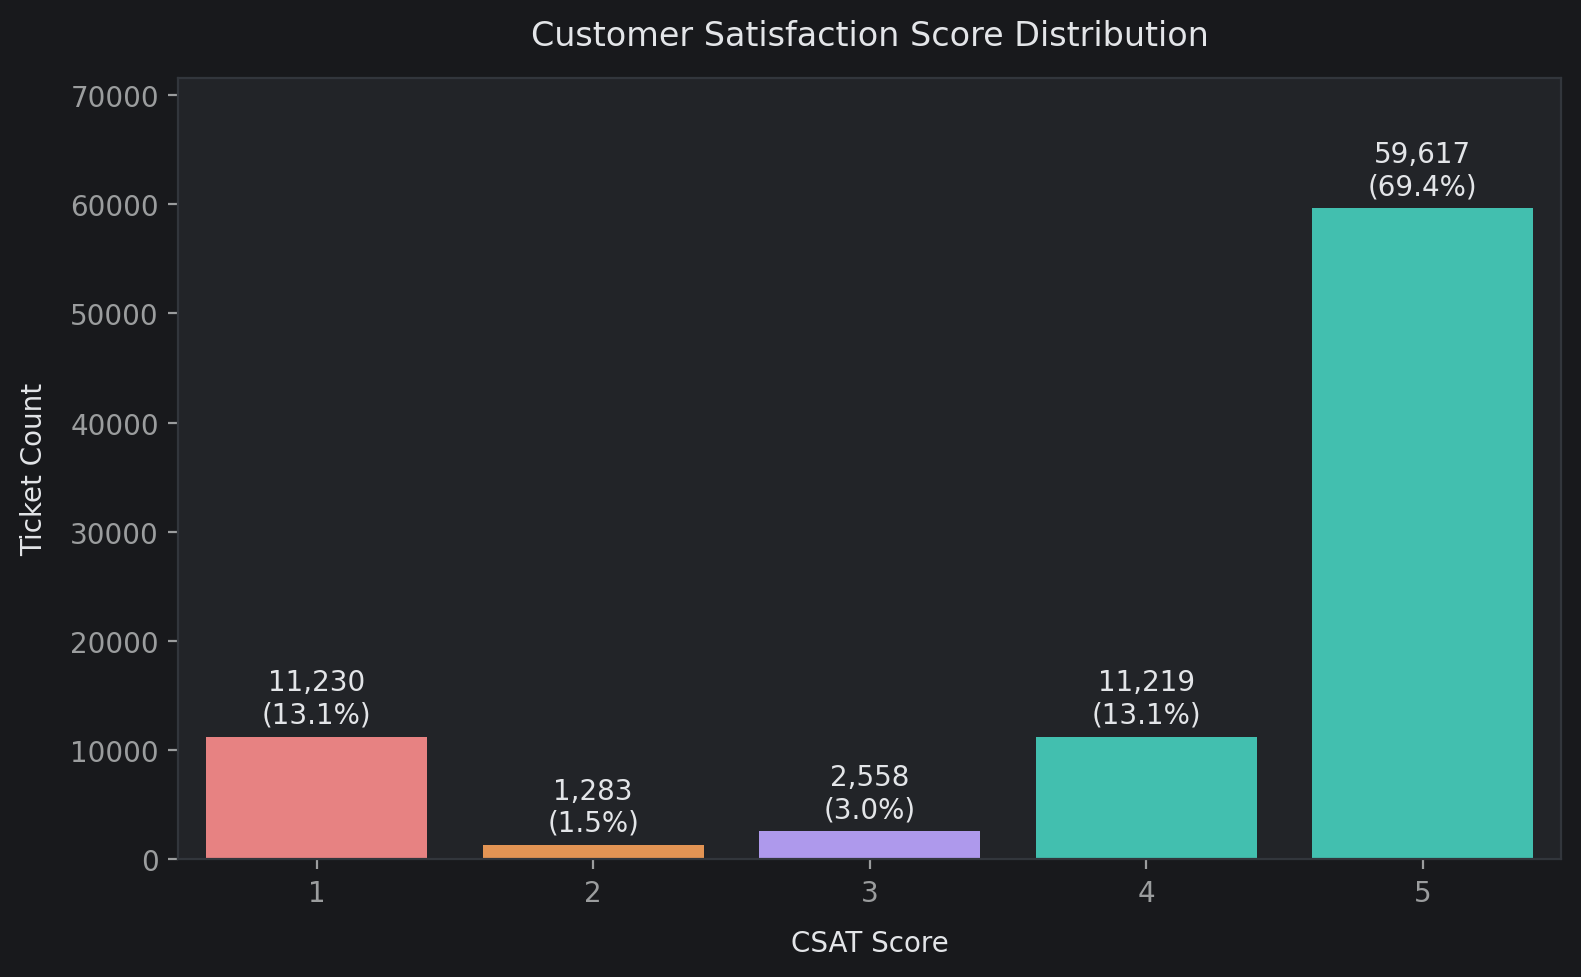

In [ ]:
# Chart 1: CSAT score distribution.
csat_counts = eda_df['csat_score'].value_counts().reindex(range(1, 6), fill_value=0)
labels = [f'{count:,}\n({count / len(eda_df):.1%})' for count in csat_counts]

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=csat_counts.index, y=csat_counts.values, palette=rating_palette)
for container, label in zip(ax.containers, labels):
    ax.bar_label(container, labels=[label], padding=3)
plt.title('Customer Satisfaction Score Distribution')
plt.xlabel('CSAT Score')
plt.ylabel('Ticket Count')
plt.ylim(0, csat_counts.max() * 1.2)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A vertical bar chart with percentage labels was selected to inspect the target variable's class balance, frequency spread, and sample density across all 5 discrete rating tiers prior to model formulation.

##### 2. What is/are the insight(s) found from the chart?

* **CSAT 5:** 59,617 tickets (**69.4%**); **CSAT 1:** 11,230 (**13.1%**).
* Scores 2, 3 and 4 have 1,283 (**1.5%**), 2,558 (**3.0%**) and 11,219 (**13.1%**) tickets respectively, out of **85,907**.
* The target is dominated by score 5. Scores 1 and 4 have similar counts; the middle ratings are not uniformly rare.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Class imbalance supports evaluating per-class recall and macro F1 alongside accuracy, and comparing class weighting during training. A majority-class predictor can score 69.4% accuracy while missing every dissatisfied ticket. Weighting is a modeling choice to validate, not a guaranteed improvement.

#### Chart - 2: Connected Handling Time Distribution

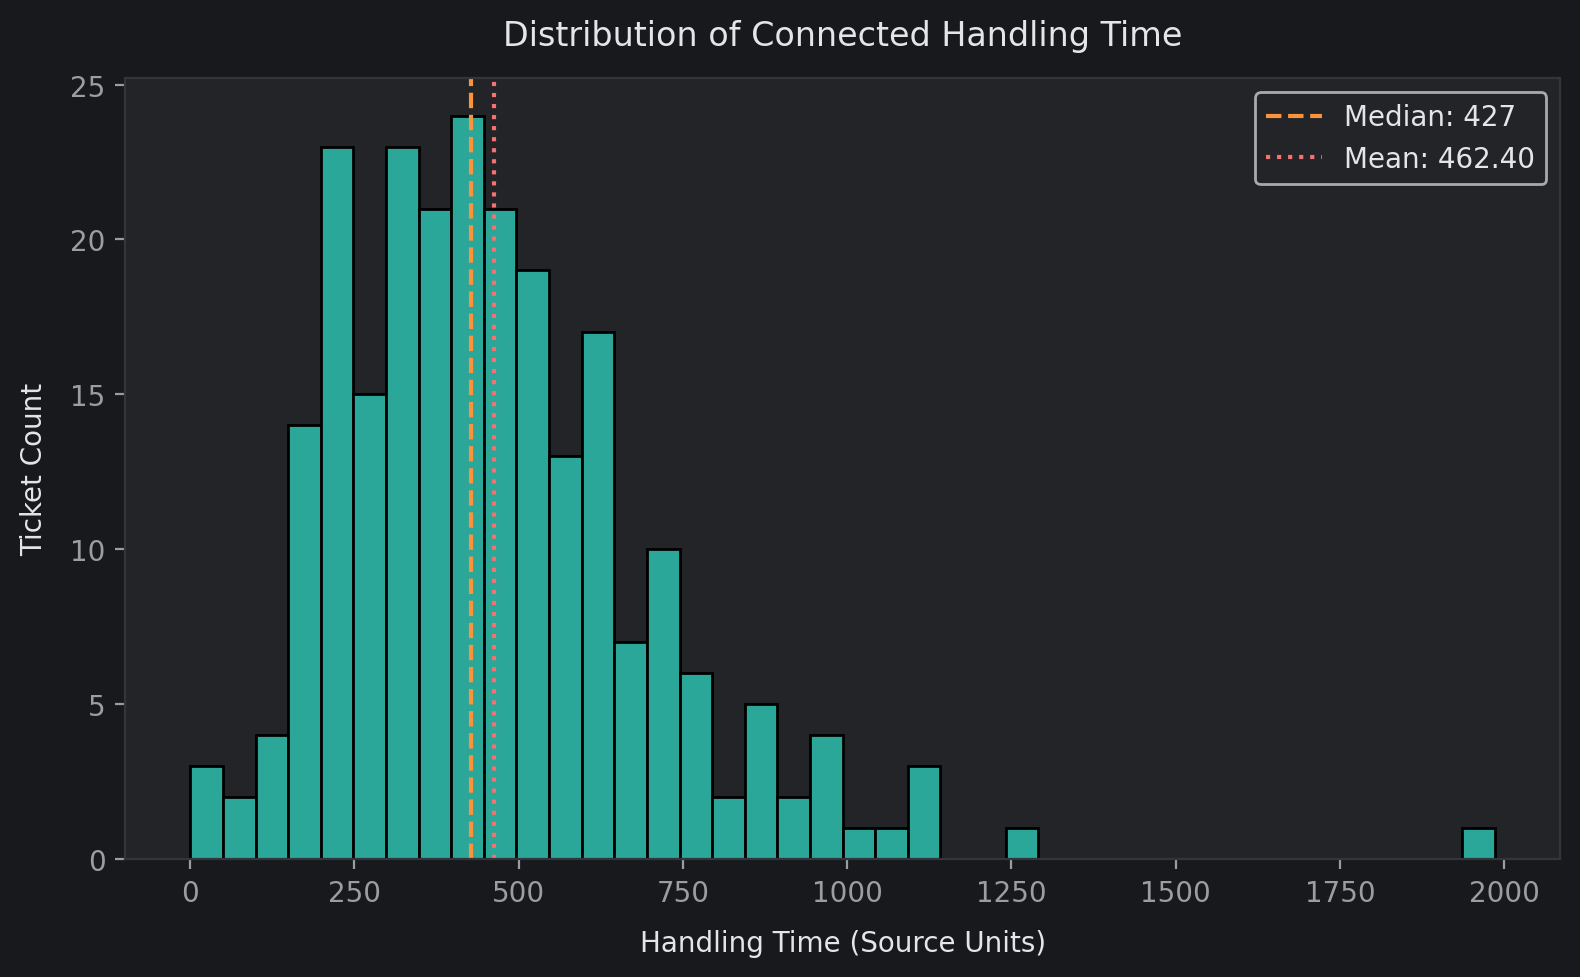

,connected_handling_time
count,242.00
mean,462.40
std,246.30
min,0.00
25%,293.00
50%,427.00
75%,592.25
99%,1108.85
max,1986.00


In [ ]:
# Chart 2: recorded handling times.
handling = eda_df['connected_handling_time'].dropna()

plt.figure(figsize=(8, 5))
sns.histplot(handling, bins=40, color=CUSTOM_THEME['teal'])
plt.axvline(handling.median(), color=CUSTOM_THEME['orange'], linestyle='--', label=f'Median: {handling.median():.0f}')
plt.axvline(handling.mean(), color=CUSTOM_THEME['coral'], linestyle=':', label=f'Mean: {handling.mean():.2f}')
plt.title('Distribution of Connected Handling Time')
plt.xlabel('Handling Time (Source Units)')
plt.ylabel('Ticket Count')
plt.legend()
plt.tight_layout()
plt.show()
display(handling.describe(percentiles=[.25, .5, .75, .99]).round(2))

##### 1. Why did you pick the specific chart?

A histogram shows the distribution of all recorded handling times. Mean and median lines help identify the typical duration and the effect of long interactions. The summary table reports the number of observations and key statistics.

##### 2. What is/are the insight(s) found from the chart?

* Only **242** handling times are observed; **85,665** are missing (**99.72%**).
* Median **427**, mean **462.40**, 99th percentile **1,108.85**, maximum **1,986** in source units indicate a right tail.
* All **242** recorded durations are included. These results describe tickets with available handling times, not all tickets.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Observed durations can inform a preliminary workload review. Coverage is too low to set platform-wide duration targets or infer that longer calls cause dissatisfaction. Improve duration collection and confirm measurement units before operational use.

#### Chart - 3: Distribution of Order Item Price

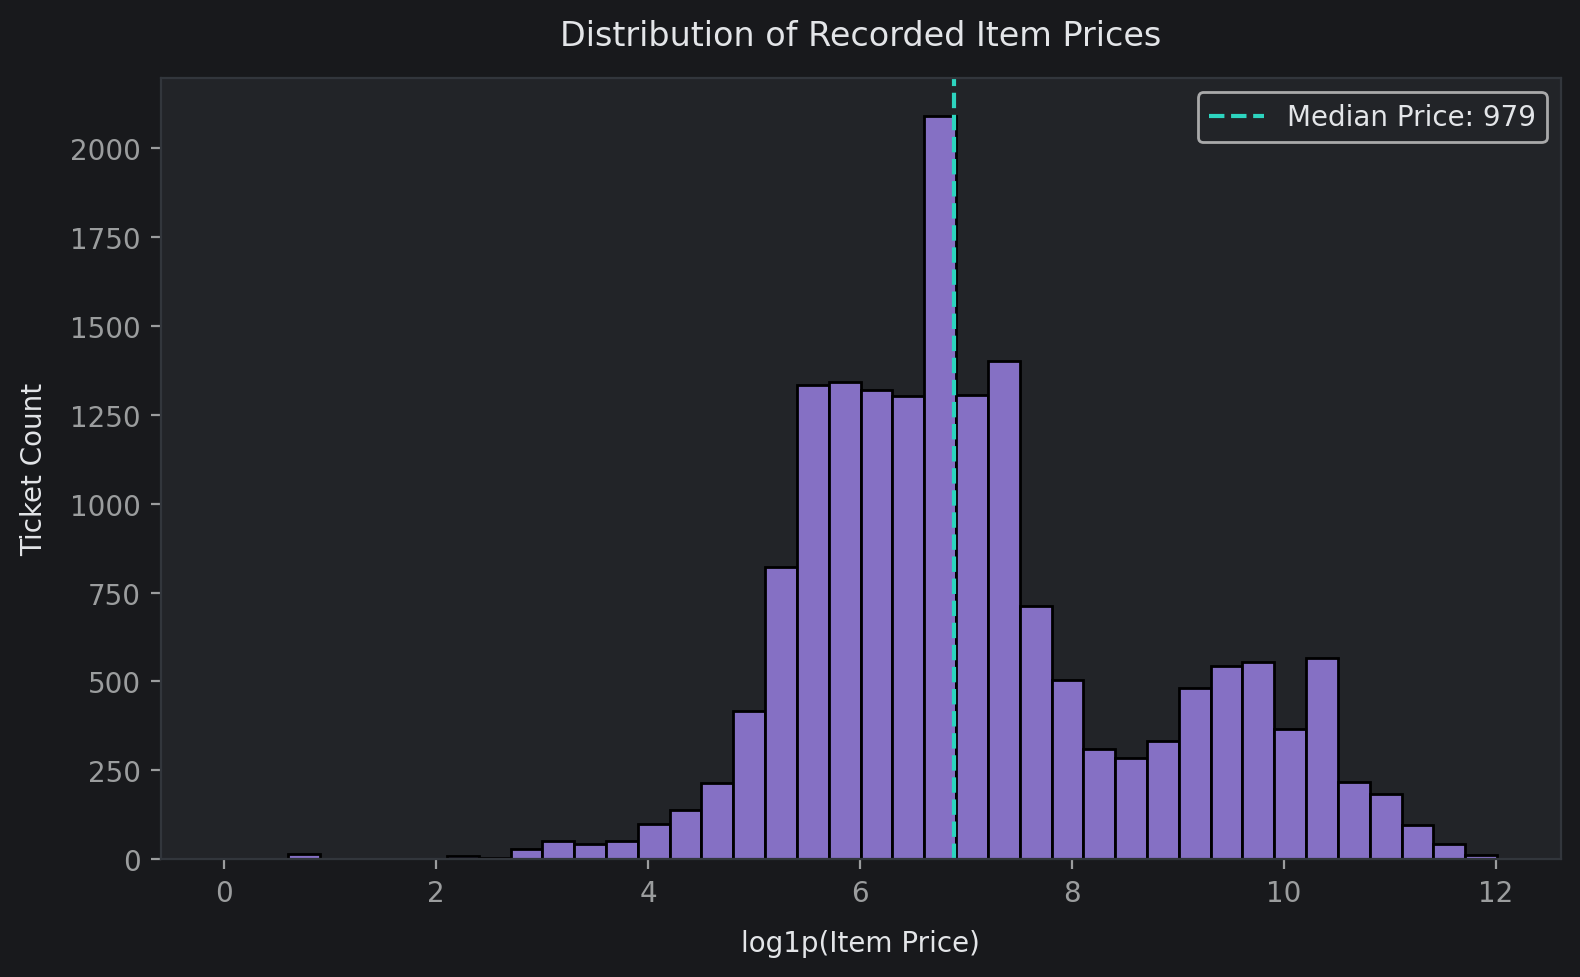

,item_price
count,17206.00
mean,5660.77
std,12825.73
min,0.00
25%,392.00
50%,979.00
75%,2699.75
99%,62998.55
max,164999.00


In [ ]:
# Chart 3: log1p keeps low prices and the long price tail visible.
prices = eda_df['item_price'].dropna()

plt.figure(figsize=(8, 5))
sns.histplot(np.log1p(prices), bins=40, color=CUSTOM_THEME['purple'])
plt.axvline(np.log1p(prices.median()), color=CUSTOM_THEME['teal'], linestyle='--', label=f'Median Price: {prices.median():.0f}')
plt.title('Distribution of Recorded Item Prices')
plt.xlabel('log1p(Item Price)')
plt.ylabel('Ticket Count')
plt.legend()
plt.tight_layout()
plt.show()
display(prices.describe(percentiles=[.25, .5, .75, .99]).round(2))

##### 1. Why did you pick the specific chart?

A histogram of log1p price shows both low prices and the long price tail without dropping zero values. The median line and summary table use the recorded prices only; missing prices are excluded.

##### 2. What is/are the insight(s) found from the chart?

* **17,206** prices are observed and **68,701** are missing (**80.0%**).
* Median **979**, mean **5,660.77**, 99th percentile **62,998.55** and maximum **164,999** in source units show substantial right skew.
* **54.0% of observed prices** are below 1,000. This percentage does not describe all support tickets.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

The observed price tail supports reviewing whether expensive-order issues need different support. Confirm currency and missingness patterns before setting thresholds. Excluding tickets with missing prices from service priority could disadvantage most customers.

#### Chart - 4: Total Interaction Volume by Support Channel

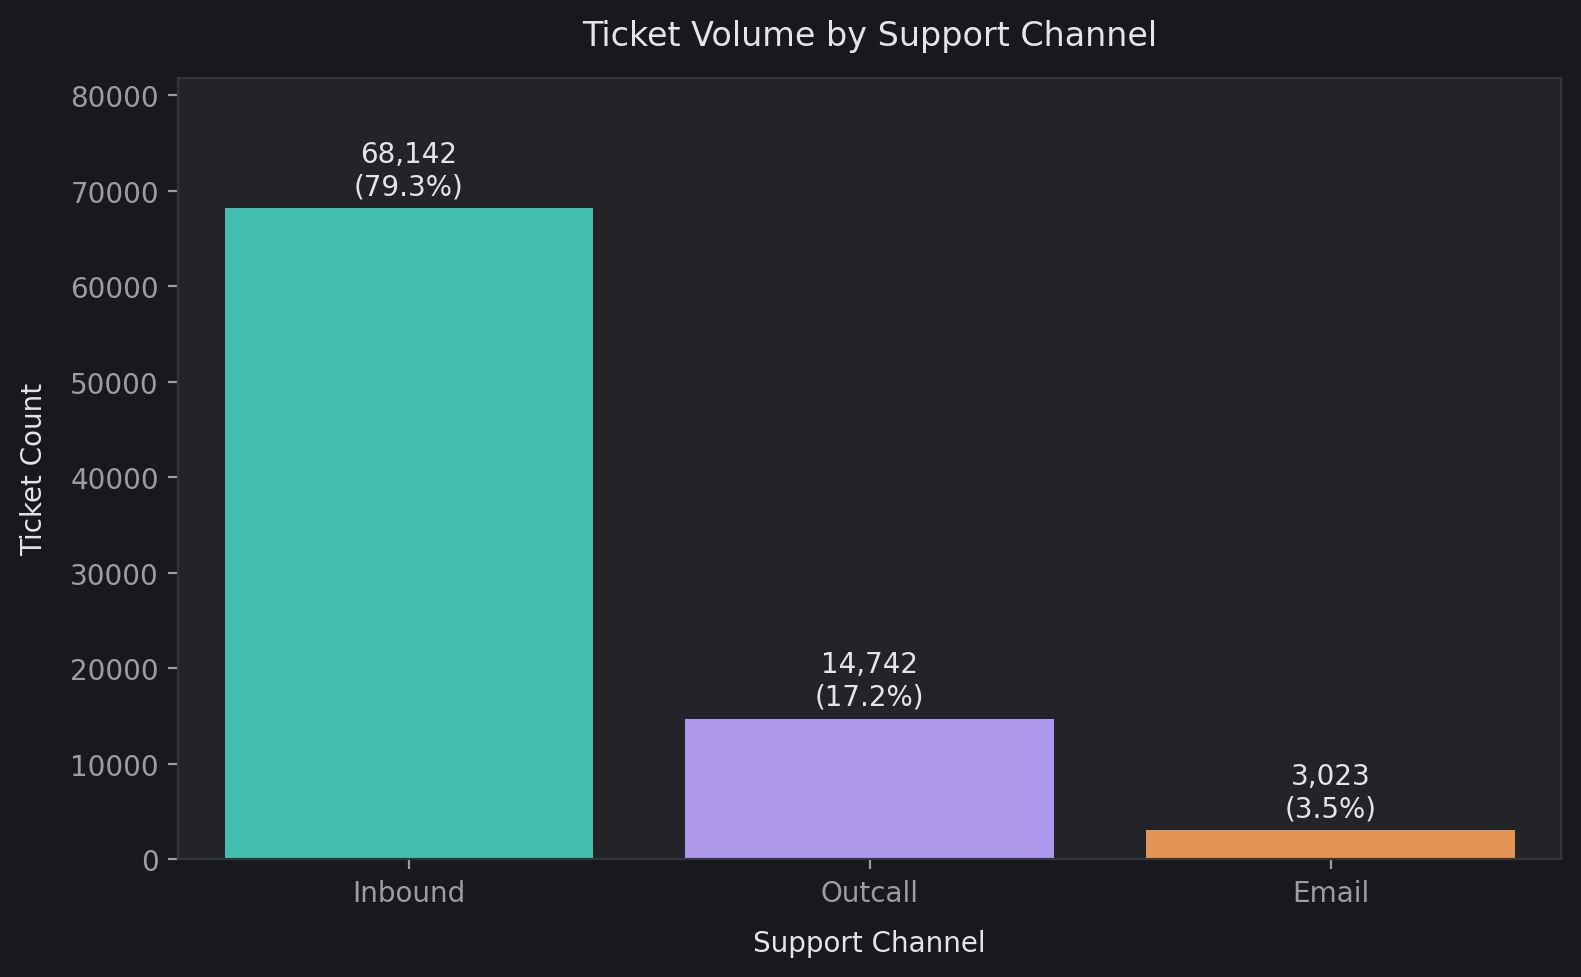

In [ ]:
# Chart 4: ticket volume by support channel.
channel_counts = eda_df['channel_name'].value_counts()
labels = [f'{count:,}\n({count / len(eda_df):.1%})' for count in channel_counts]

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=channel_counts.index, y=channel_counts.values, palette=[CUSTOM_THEME['teal'], CUSTOM_THEME['purple'], CUSTOM_THEME['orange']])
for container, label in zip(ax.containers, labels):
    ax.bar_label(container, labels=[label], padding=3)
plt.title('Ticket Volume by Support Channel')
plt.xlabel('Support Channel')
plt.ylabel('Ticket Count')
plt.ylim(0, channel_counts.max() * 1.2)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A vertical bar chart with count and percentage annotations was selected to evaluate the channel distribution and determine where customer volume concentrates across support touchpoints.

##### 2. What is/are the insight(s) found from the chart?

* **Inbound:** 68,142 tickets (**79.3%**).
* **Outcall:** 14,742 (**17.2%**); **Email:** 3,023 (**3.5%**).
* These three recorded channels account for all **85,907** tickets; there is no separate web-chat category.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Inbound volume supports prioritizing capacity planning for that queue. Email's lower share does not establish lower business importance or lower staffing needs; combine volume with workload and service outcomes before reallocating resources.

#### Chart - 5: Ticket Handling Distribution by Agent Experience Cohort

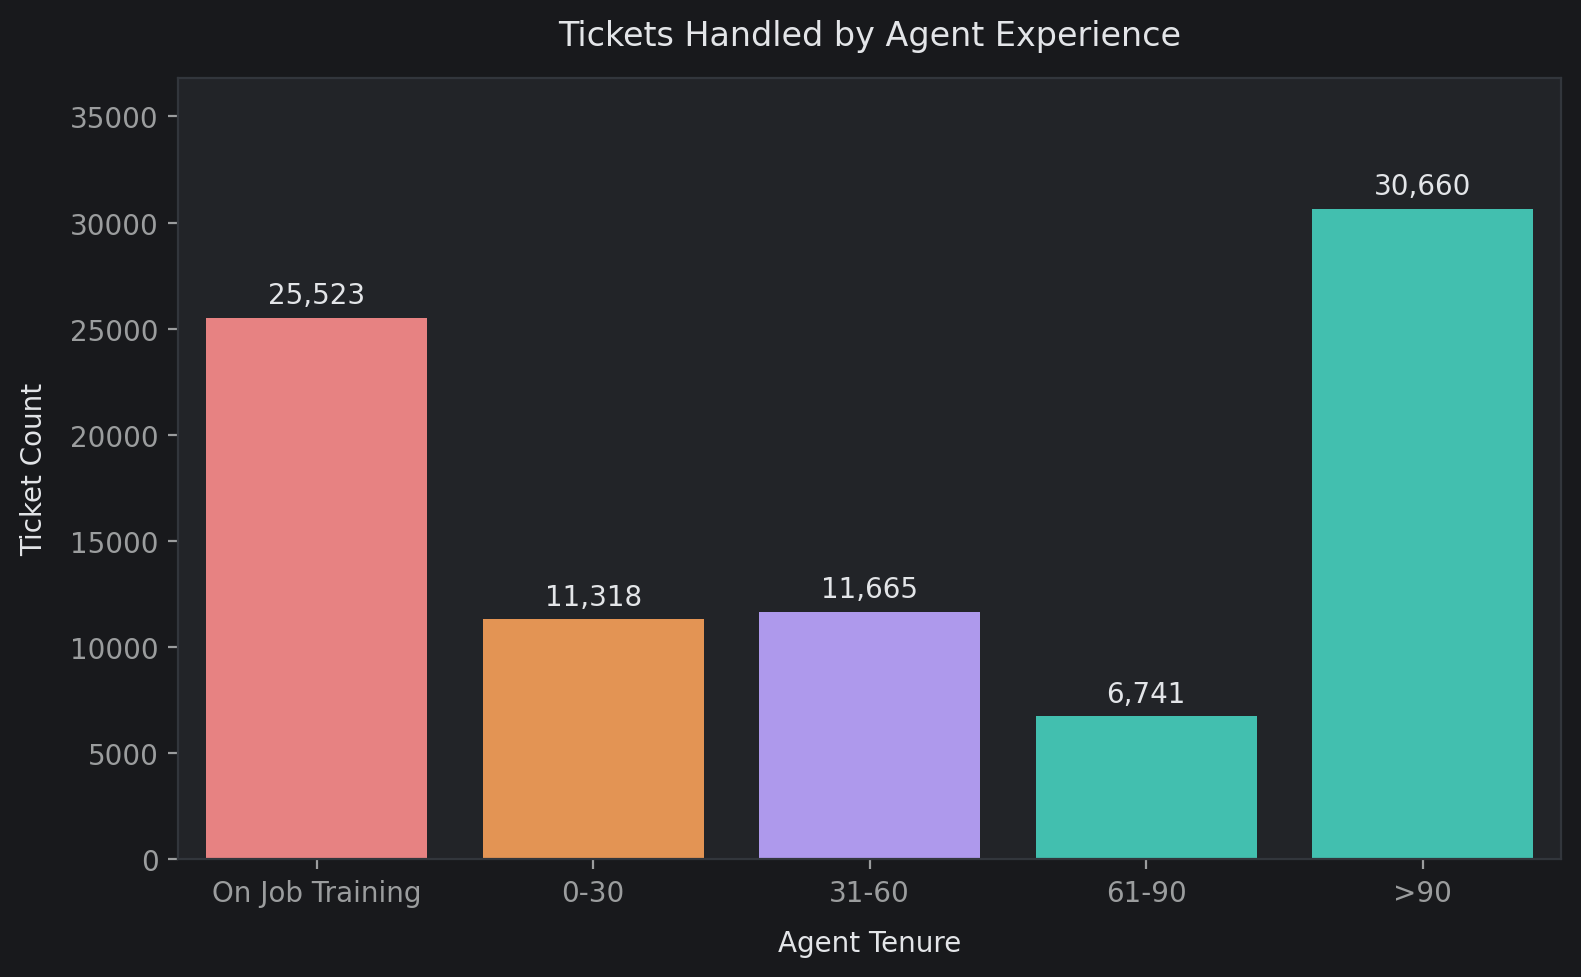

In [ ]:
# Chart 5: ticket volume by agent experience.
tenure_counts = eda_df['tenure_bucket'].value_counts().reindex(tenure_order, fill_value=0)

labels = [f'{count:,}' for count in tenure_counts]

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=tenure_counts.index, y=tenure_counts.values, palette=rating_palette)
for container, label in zip(ax.containers, labels):
    ax.bar_label(container, labels=[label], padding=3)
plt.title('Tickets Handled by Agent Experience')
plt.xlabel('Agent Tenure')
plt.ylabel('Ticket Count')
plt.ylim(0, tenure_counts.max() * 1.2)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

An ordered categorical bar chart was selected to examine workforce experience distribution and measure the proportion of tickets handled by junior versus senior personnel.

##### 2. What is/are the insight(s) found from the chart?

* **>90 days:** 30,660 tickets (**35.7%**), the largest cohort.
* **On Job Training:** 25,523 (**29.7%**); **0–30:** 11,318 (**13.2%**); **31–60:** 11,665 (**13.6%**); **61–90:** 6,741 (**7.8%**).
* Trainees plus 0–30 days handle **42.9%** of tickets. These are ticket shares, not agent headcounts; the chart includes every recorded tenure label.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

The substantial trainee/early-tenure ticket share supports reviewing coaching coverage and queue assignment. Ticket volume alone does not measure workforce size, productivity or individual performance.

### Bivariate Analysis (Charts 6 – 10)
Evaluating pairwise dependencies between operational predictors and the CSAT score target.

#### Chart - 6: Average CSAT Score across Support Channels

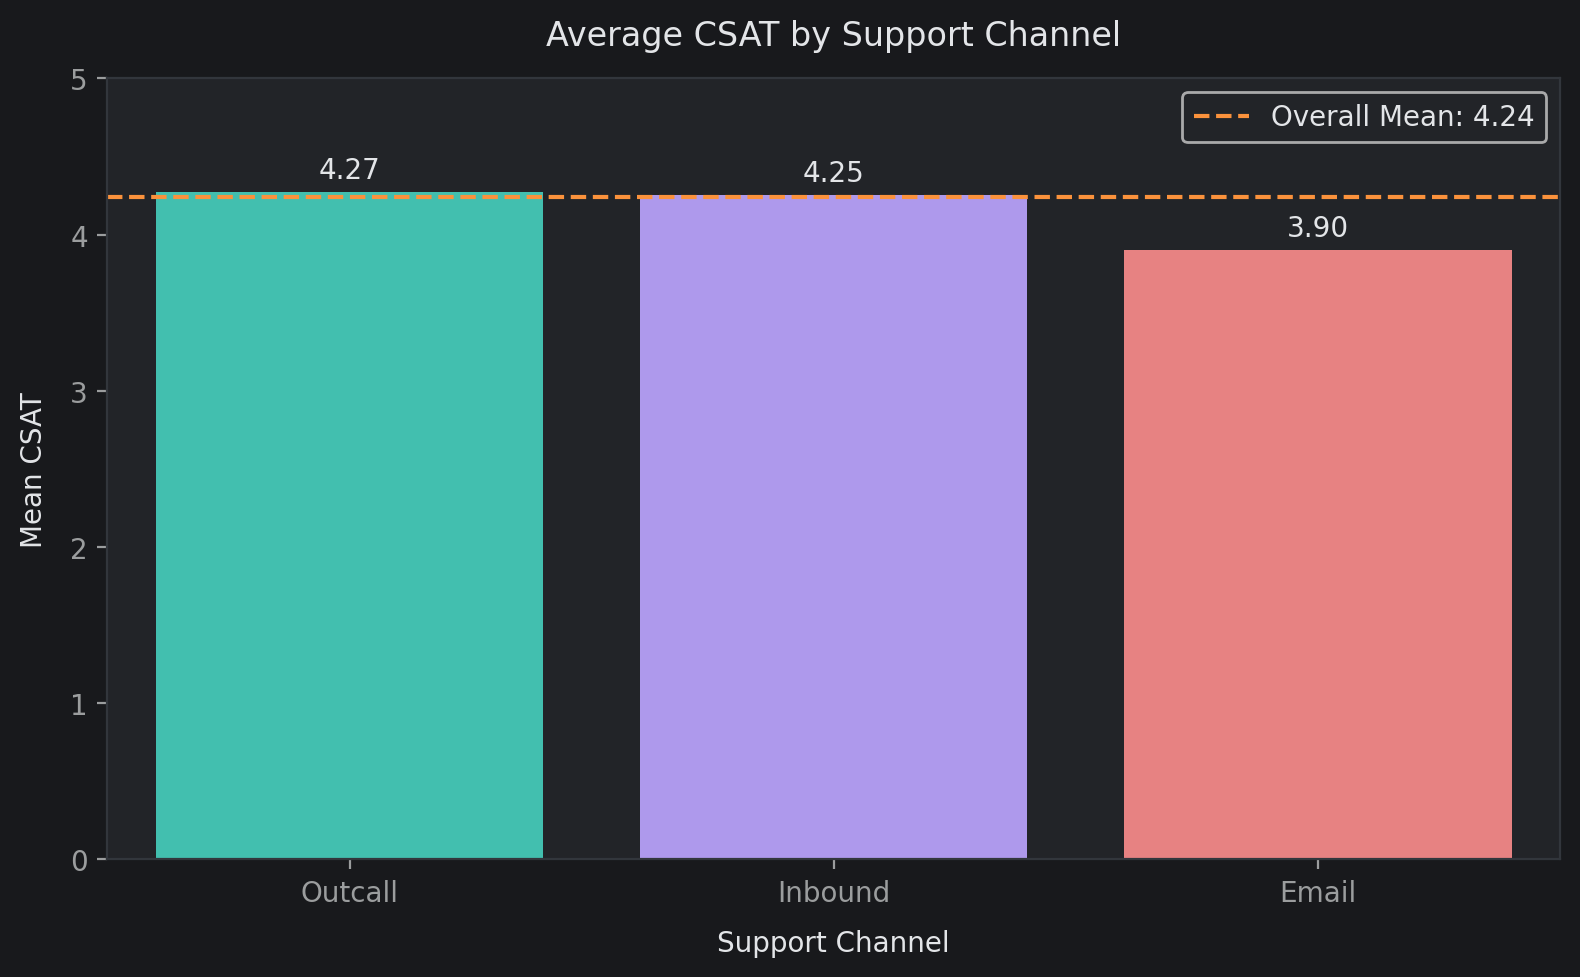

,mean,count
channel_name,,
Outcall,4.270,14742
Inbound,4.251,68142
Email,3.899,3023


In [ ]:
# Chart 6: average CSAT by channel.
channel_csat = eda_df.groupby('channel_name')['csat_score'].agg(['mean', 'count']).sort_values('mean', ascending=False)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=channel_csat.index, y=channel_csat['mean'], palette=[CUSTOM_THEME['teal'], CUSTOM_THEME['purple'], CUSTOM_THEME['coral']])
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)
plt.axhline(overall_mean, color=CUSTOM_THEME['orange'], linestyle='--', label=f'Overall Mean: {overall_mean:.2f}')
plt.title('Average CSAT by Support Channel')
plt.xlabel('Support Channel')
plt.ylabel('Mean CSAT')
plt.ylim(0, 5)
plt.legend()
plt.tight_layout()
plt.show()
display(channel_csat.round(3))

##### 1. Why did you pick the specific chart?

A categorical bar chart with a benchmark line was chosen to compare average satisfaction ratings across different contact channels against overall performance.

##### 2. What is/are the insight(s) found from the chart?

* Mean CSAT is **4.270 Outcall** (n=14,742), **4.251 Inbound** (n=68,142), and **3.899 Email** (n=3,023).
* Overall mean is **4.242**. Email is below this baseline; telephony channel means are below 4.3.
* Differences may reflect issue mix or customer selection, rather than channel effects alone.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Review email workflows and issue mix because its mean score is lower. Test response-time or routing changes before rollout; the bar chart does not identify slow responses as the cause.

#### Chart - 7: Average CSAT Score across Agent Experience Bands

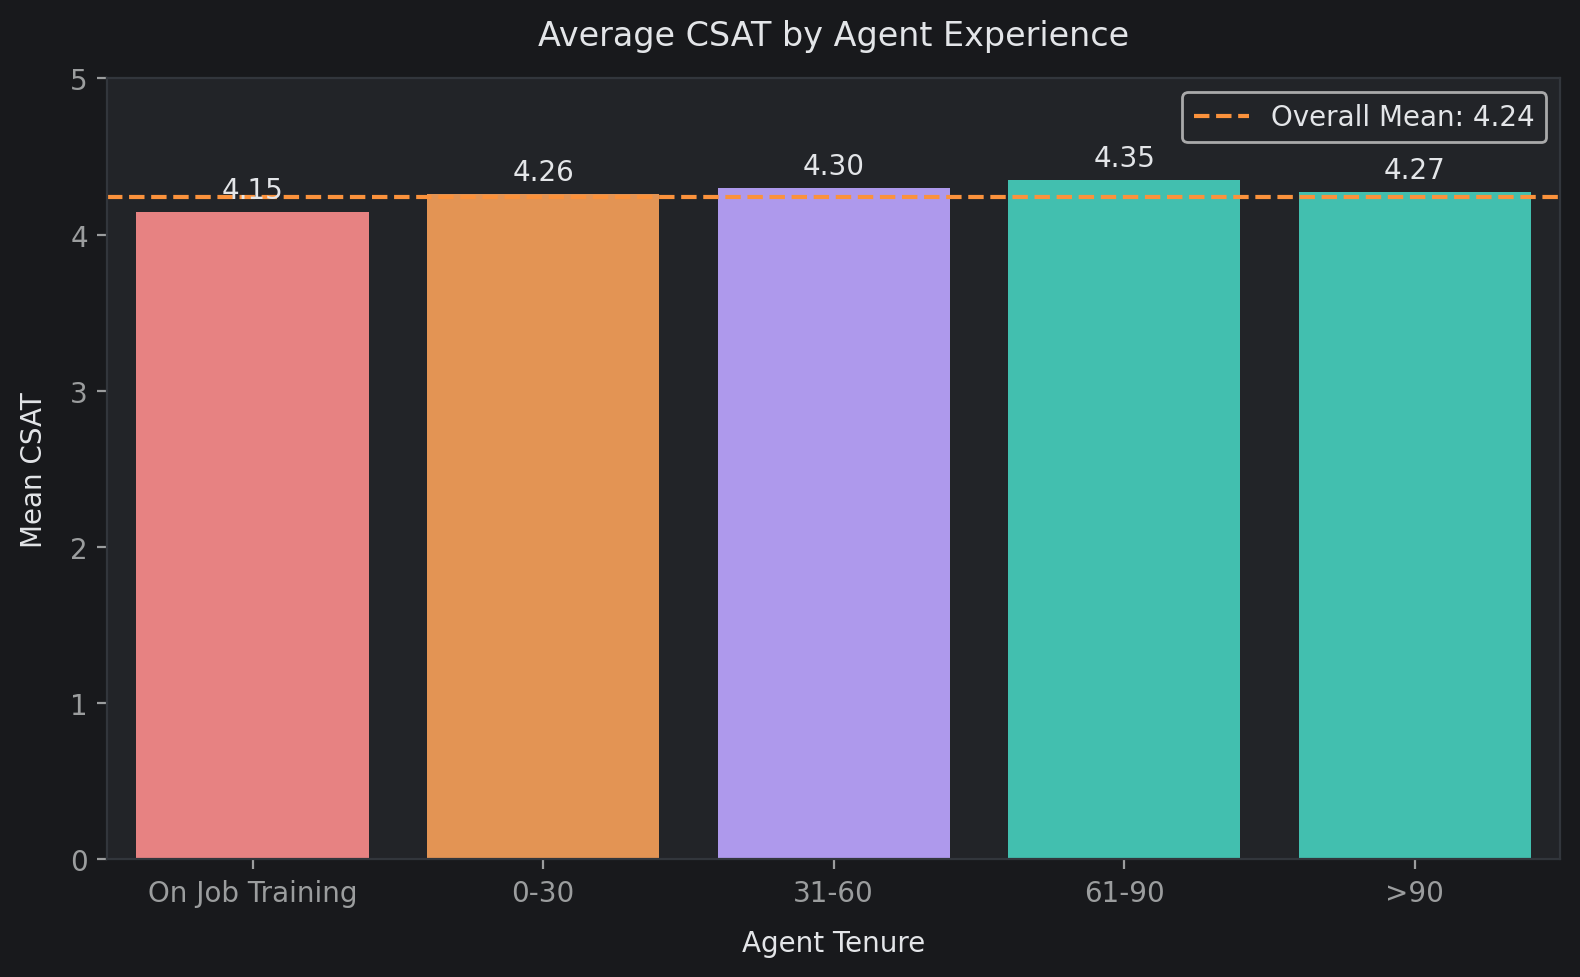

,mean,count
tenure_bucket,,
On Job Training,4.145,25523
0-30,4.259,11318
31-60,4.296,11665
61-90,4.347,6741
>90,4.273,30660


In [ ]:
# Chart 7: average CSAT by agent experience.
tenure_summary = eda_df.groupby('tenure_bucket')['csat_score'].agg(['mean', 'count']).reindex(tenure_order)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=tenure_summary.index, y=tenure_summary['mean'], palette=rating_palette)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)
plt.axhline(overall_mean, color=CUSTOM_THEME['orange'], linestyle='--', label=f'Overall Mean: {overall_mean:.2f}')
plt.title('Average CSAT by Agent Experience')
plt.xlabel('Agent Tenure')
plt.ylabel('Mean CSAT')
plt.ylim(0, 5)
plt.legend()
plt.tight_layout()
plt.show()
display(tenure_summary.round(3))

##### 1. Why did you pick the specific chart?

An ordered bar plot compares mean scores across tenure bands against the same overall baseline used in Chart 6. The accompanying counts show unequal ticket volume. The comparison is descriptive and does not measure the causal effect of experience.

##### 2. What is/are the insight(s) found from the chart?

* Mean CSAT progresses from **4.145** (training) to **4.259** (0–30), **4.296** (31–60), and **4.347** (61–90), then falls to **4.273** (>90).
* Training has the lowest mean; **61–90 days**, not >90 days, has the highest.
* The pattern is not strictly increasing. Ticket mix and assignment could contribute to differences.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Compare coaching and assignment practices between training and the higher-scoring cohorts. Avoid assuming every additional tenure band improves satisfaction, or using aggregate means to rate individual agents.

#### Chart - 8: Item Price Distribution by Satisfaction Cohort

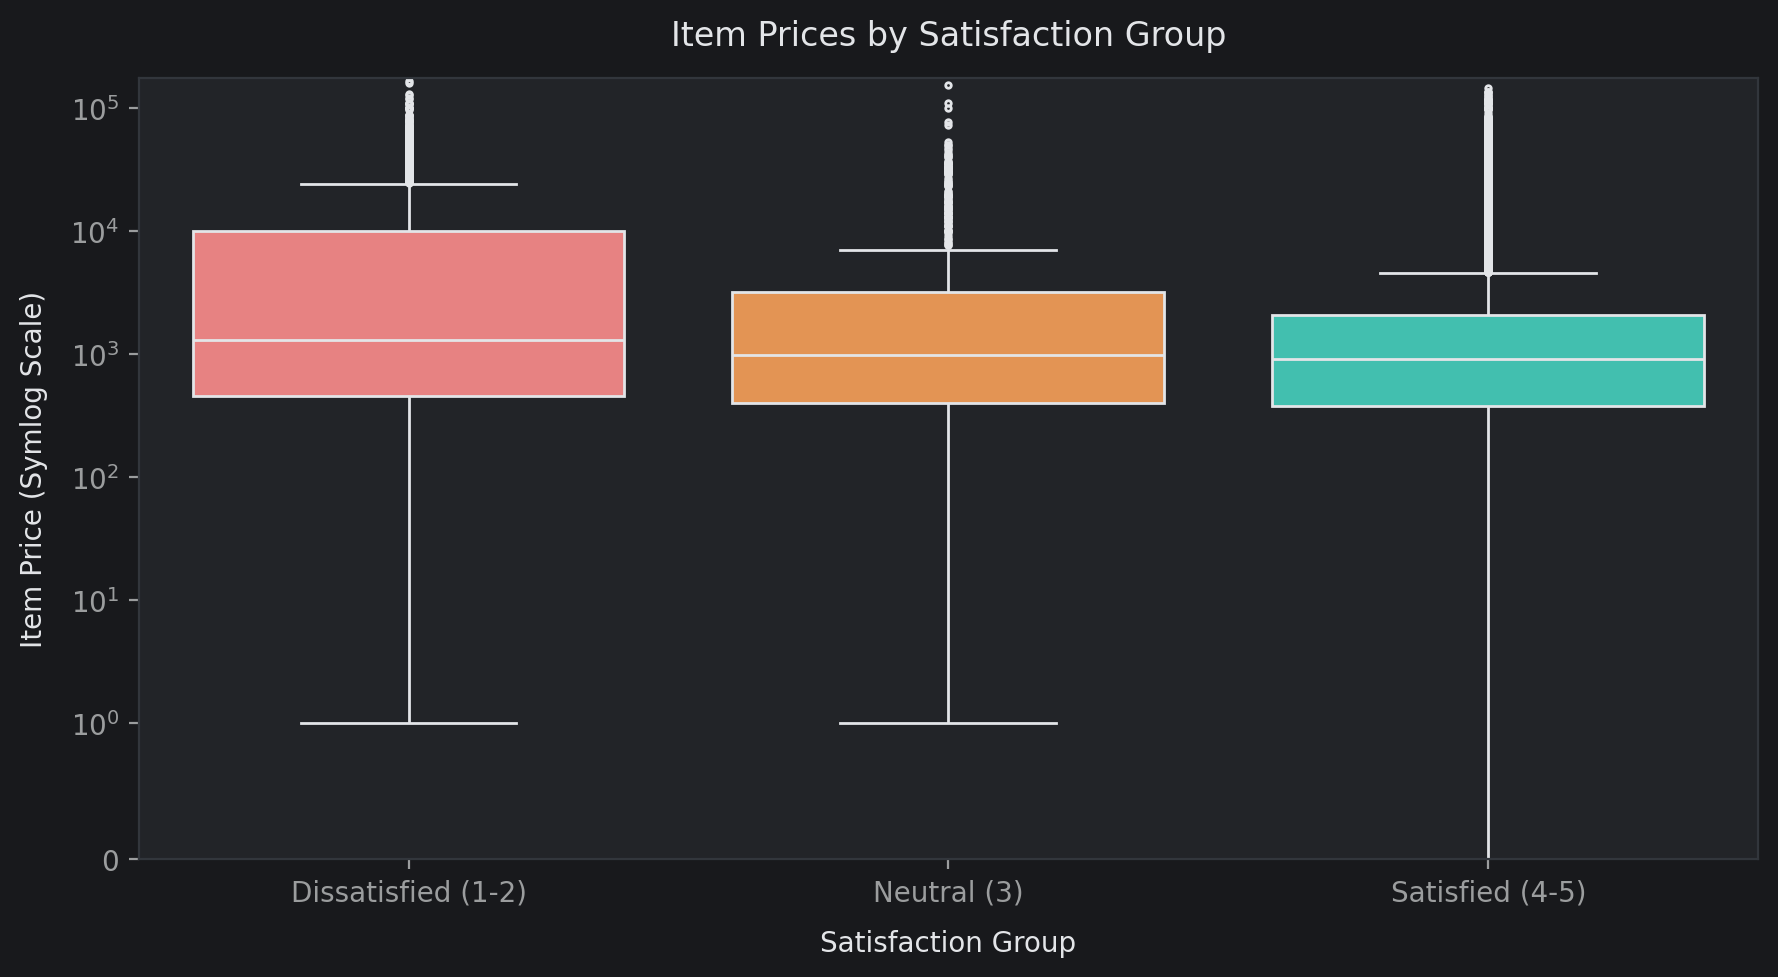

,n,median,q25,q75
satisfaction_cohort,,,,
Dissatisfied (1-2),3700,1299.0,449.0,9999.0
Neutral (3),568,977.0,399.0,3182.5
Satisfied (4-5),12938,899.0,379.0,2053.0


In [ ]:
# Chart 8: price distributions, including zeros and outliers.
price_plot = eda_df.dropna(subset=['item_price'])

plt.figure(figsize=(9, 5))
sns.boxplot(data=price_plot, x='satisfaction_cohort', y='item_price', order=cohort_order,
            palette=cohort_palette, fliersize=2, linecolor=CUSTOM_THEME['text'])
plt.yscale('symlog', linthresh=1)
plt.ylim(bottom=0)
plt.title('Item Prices by Satisfaction Group')
plt.xlabel('Satisfaction Group')
plt.ylabel('Item Price (Symlog Scale)')
plt.tight_layout()
plt.show()
price_summary = price_plot.groupby('satisfaction_cohort', observed=True)['item_price'].agg(
    n='count', median='median', q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))
display(price_summary.round(2))

##### 1. Why did you pick the specific chart?

Boxplots compare observed price medians and interquartile ranges across the same three CSAT cohorts. A symlog y-axis keeps zeros and the full price range visible; outlier markers are retained. The summary table reports each cohort's observed n and quartiles.

##### 2. What is/are the insight(s) found from the chart?

* Observed price medians are **1,299** for dissatisfied (n=3,700), **977** for neutral (n=568), and **899** for satisfied tickets (n=12,938).
* Dissatisfied IQR is **449–9,999**, versus **379–2,053** for satisfied tickets.
* Higher prices and a broader price range are associated with dissatisfaction in the observed-price subset. The plot does not establish that price raises expectations or causes low scores.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Investigate expensive-order complaints and test support improvements using the observed association. Missing prices affect 80.0% of tickets, so price alone is unsuitable for prioritizing the entire queue.

#### Chart - 9: Median Connected Handling Time by CSAT Score

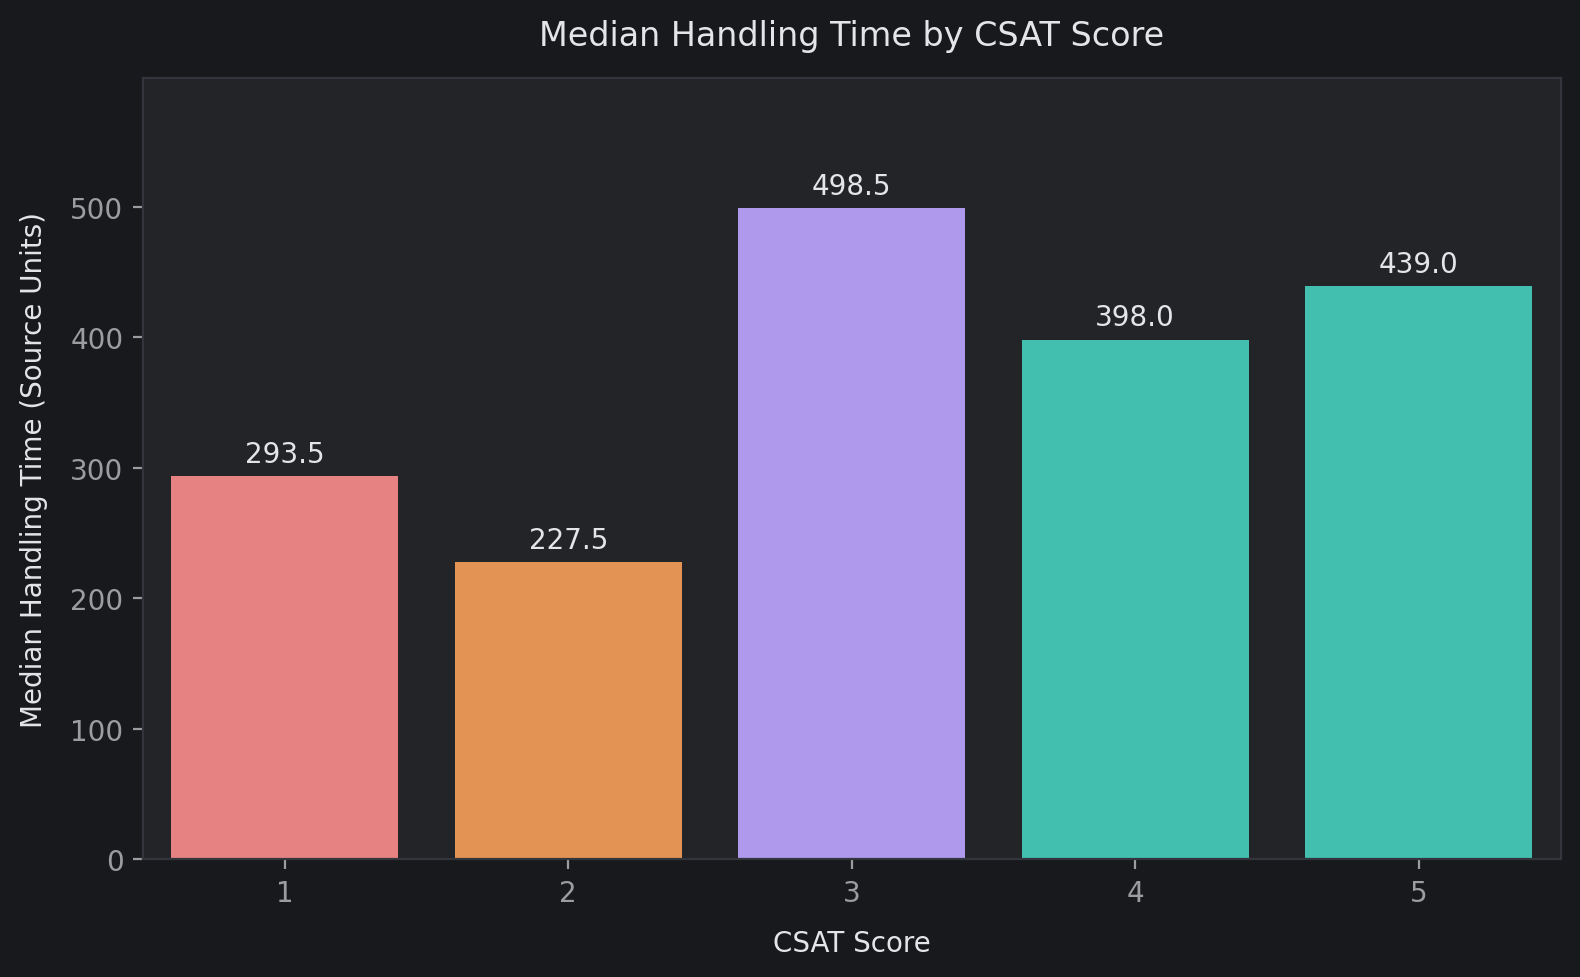

,count,median,mean
csat_score,,,
1,16,293.5,452.188
2,4,227.5,296.000
3,6,498.5,488.000
4,33,398.0,439.879
5,183,439.0,470.153


In [ ]:
# Chart 9: median recorded handling time by score.
handling_summary = eda_df.groupby('csat_score')['connected_handling_time'].agg(['count', 'median', 'mean'])

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=handling_summary.index, y=handling_summary['median'], palette=rating_palette)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)
plt.title('Median Handling Time by CSAT Score')
plt.xlabel('CSAT Score')
plt.ylabel('Median Handling Time (Source Units)')
plt.ylim(0, handling_summary['median'].max() * 1.2)
plt.tight_layout()
plt.show()
display(handling_summary.round(3))

##### 1. Why did you pick the specific chart?

A bar chart compares observed median handling time at each exact CSAT score. Medians resist extreme values; the accompanying count/mean/median table exposes how little evidence supports each bar. Imputed durations are excluded.

##### 2. What is/are the insight(s) found from the chart?

* Observed medians for scores **1, 2, 3, 4, 5** are **293.5, 227.5, 498.5, 398.0, 439.0** in source units.
* Counts are only **16, 4, 6, 33, 183**, respectively.
* Score 3 has the highest median; score 1 does not. There is no monotonic decline in duration as satisfaction rises.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Improve duration coverage before setting alerts or agent targets. Tiny low-score groups and non-monotonic medians do not support the claim that longer interactions signal dissatisfaction across the platform.

#### Chart - 10: Average CSAT Score across Primary Issue Categories

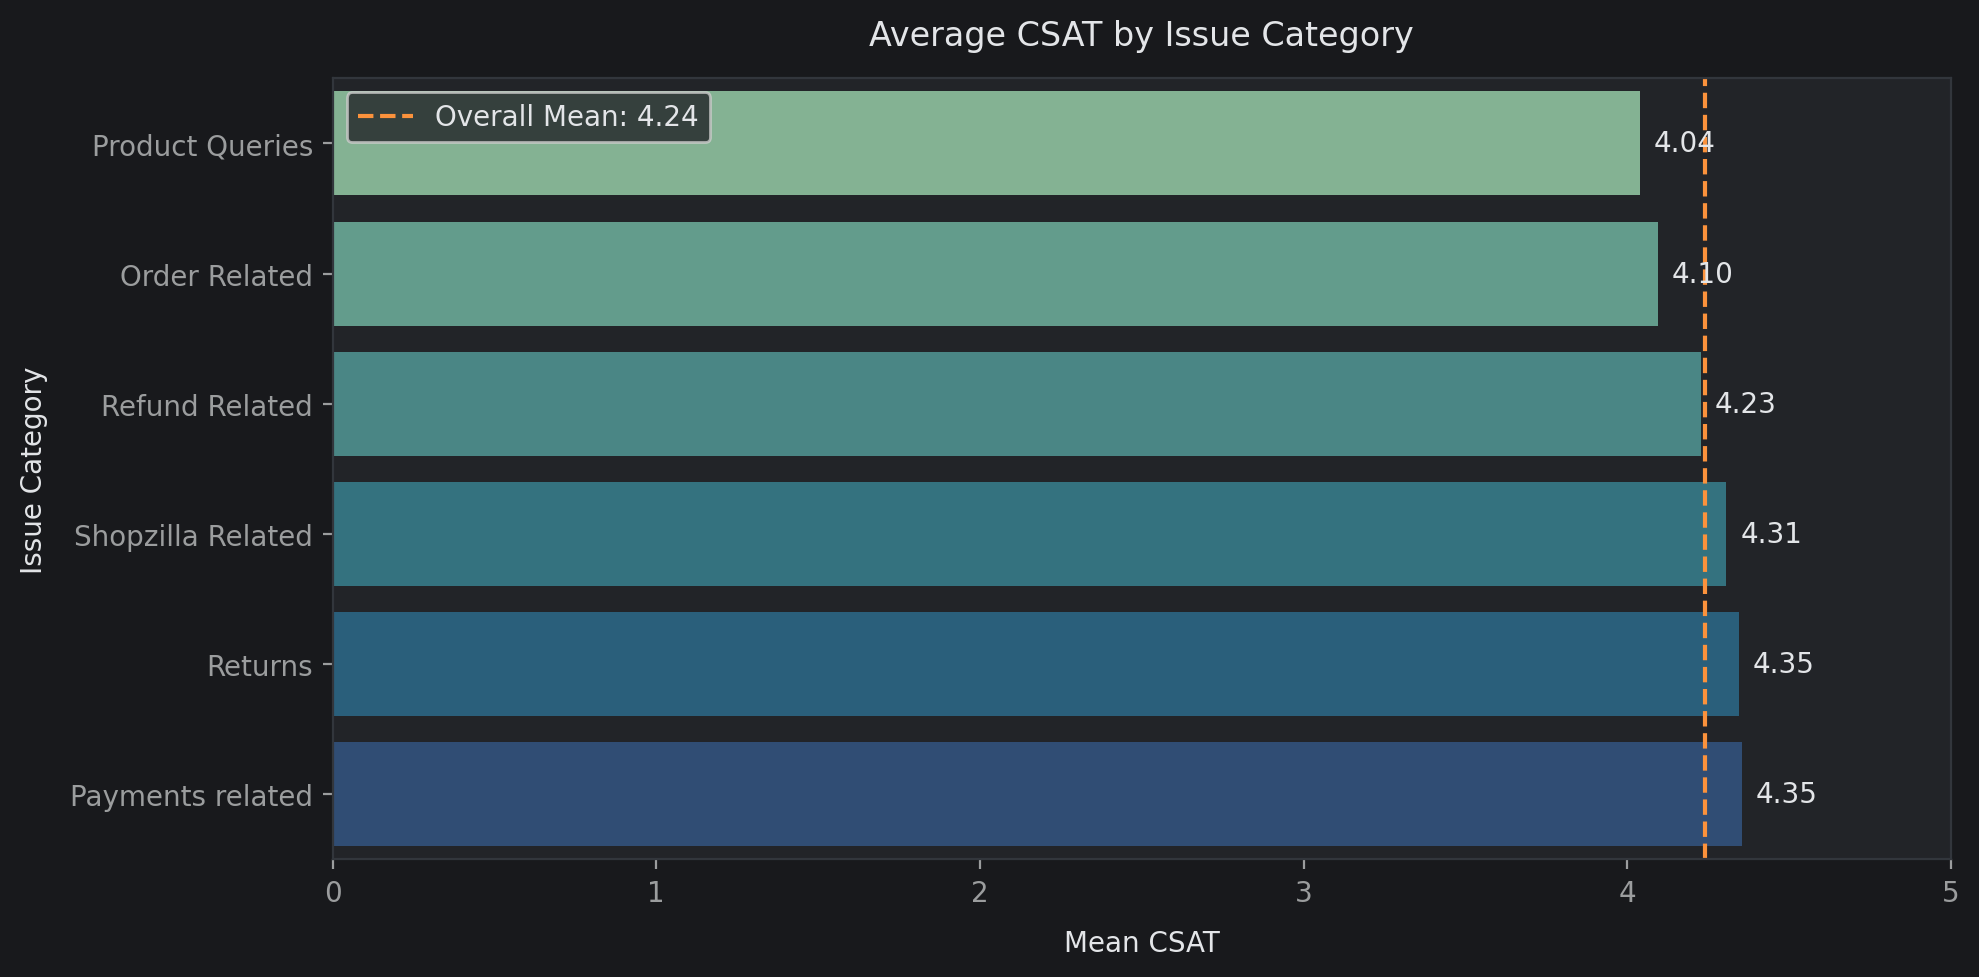

,mean,count
category,,
Product Queries,4.040,3692
Order Related,4.096,23215
Refund Related,4.227,4550
Shopzilla Related,4.307,2792
Returns,4.346,44097
Payments related,4.355,2327


In [ ]:
# Chart 10: average scores for the six largest issue categories.
category_data = eda_df[eda_df['category'].isin(top_cats)]
category_summary = category_data.groupby('category')['csat_score'].agg(['mean', 'count']).sort_values('mean')

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=category_summary['mean'], y=category_summary.index, palette='crest')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=5)
plt.axvline(overall_mean, color=CUSTOM_THEME['orange'], linestyle='--', label=f'Overall Mean: {overall_mean:.2f}')
plt.title('Average CSAT by Issue Category')
plt.xlabel('Mean CSAT')
plt.ylabel('Issue Category')
plt.xlim(0, 5)
plt.legend()
plt.tight_layout()
plt.show()
display(category_summary.round(3))

##### 1. Why did you pick the specific chart?

A horizontal bar chart ranks mean CSAT within the six categories with the most tickets. The accompanying table gives counts; the baseline is the full-dataset mean. The ranking applies to this selected set, not every category.

##### 2. What is/are the insight(s) found from the chart?

* Among the **six largest categories**, **Product Queries** is lowest (**4.040**, n=3,692), followed by **Order Related** (**4.096**, n=23,215).
* **Refund Related: 4.227**, **Shopzilla Related: 4.307**, **Returns: 4.346**, **Payments related: 4.355**.
* Returns has **44,097** tickets and scores above the overall **4.242** mean. Cancellation is not in this top-six comparison.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Prioritize investigating Product Queries and Order Related workflows within this comparison. Returns deserves capacity attention because of its volume, but its mean score does not identify it as the worst-performing category. Avoid extending the ranking to excluded categories.

### Multivariate Analysis (Charts 11 – 15)
Uncovering higher-order interactions, shift dynamics, correlation structures, and multi-dimensional cluster separations.

#### Chart - 11: Mean CSAT by Agent Shift & Support Channel

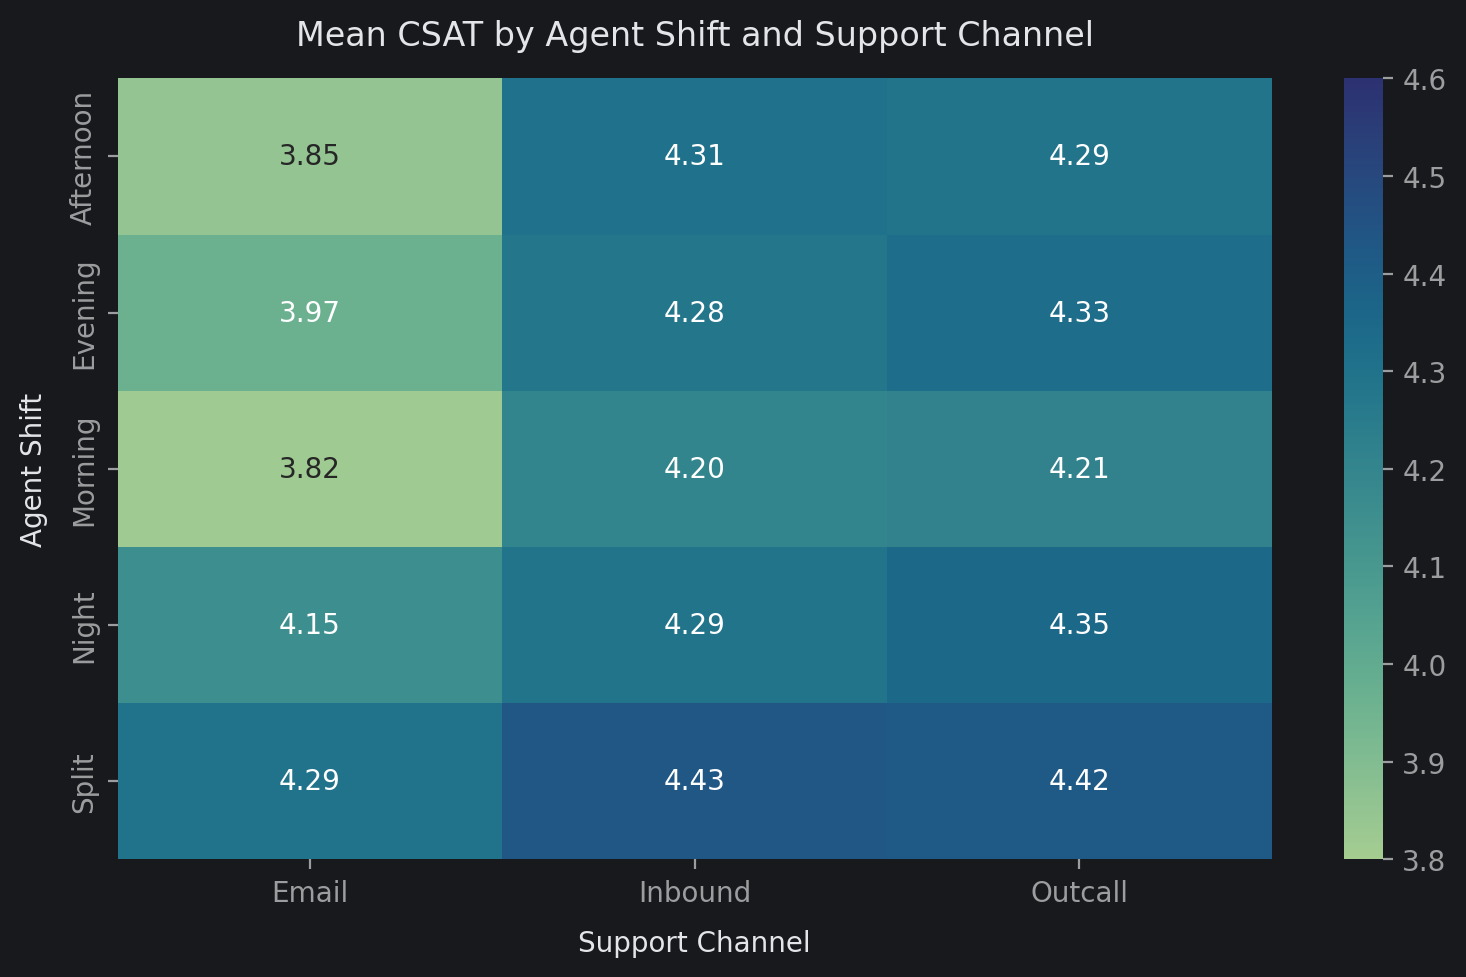

Ticket counts for each shift and channel:


channel_name,Email,Inbound,Outcall
agent_shift,,,
Afternoon,160,4843,837
Evening,1160,26380,6137
Morning,1536,32558,7332
Night,65,1131,120
Split,102,3230,316


In [ ]:
# Chart 11: mean CSAT by shift and channel.
shift_channel_csat = eda_df.pivot_table(index='agent_shift', columns='channel_name', values='csat_score', aggfunc='mean')
shift_channel_counts = eda_df.pivot_table(index='agent_shift', columns='channel_name', values='csat_score', aggfunc='count')

plt.figure(figsize=(8, 5))
sns.heatmap(shift_channel_csat, annot=True, fmt='.2f', cmap='crest', vmin=3.8, vmax=4.6)
plt.title('Mean CSAT by Agent Shift and Support Channel')
plt.xlabel('Support Channel')
plt.ylabel('Agent Shift')
plt.tight_layout()
plt.show()
print('Ticket counts for each shift and channel:')
display(shift_channel_counts)

##### 1. Why did you pick the specific chart?

A heatmap compares average CSAT across shifts and support channels. The shared **3.8–4.6** color range makes differences visible and keeps the colors comparable with Chart 13. The table below gives the number of tickets behind each average.

##### 2. What is/are the insight(s) found from the chart?

* **Morning Email** has the lowest mean (**3.816**, n=1,536); Afternoon Email is **3.850** (n=160).
* Evening Email is **3.967** (n=1,160); **Split Email is 4.294** (n=102), so Split is not the poorest email shift.
* **Split Inbound: 4.432** (n=3,230) is the highest cell. Counts differ substantially, and shift composition may affect comparisons.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Review morning/afternoon email operations and compare their issue mix before changing staffing. Do not shift resources solely because a small cell has an extreme mean; show counts alongside every shift comparison.

#### Chart - 12: Handling Time vs. Item Price by Satisfaction Cohort

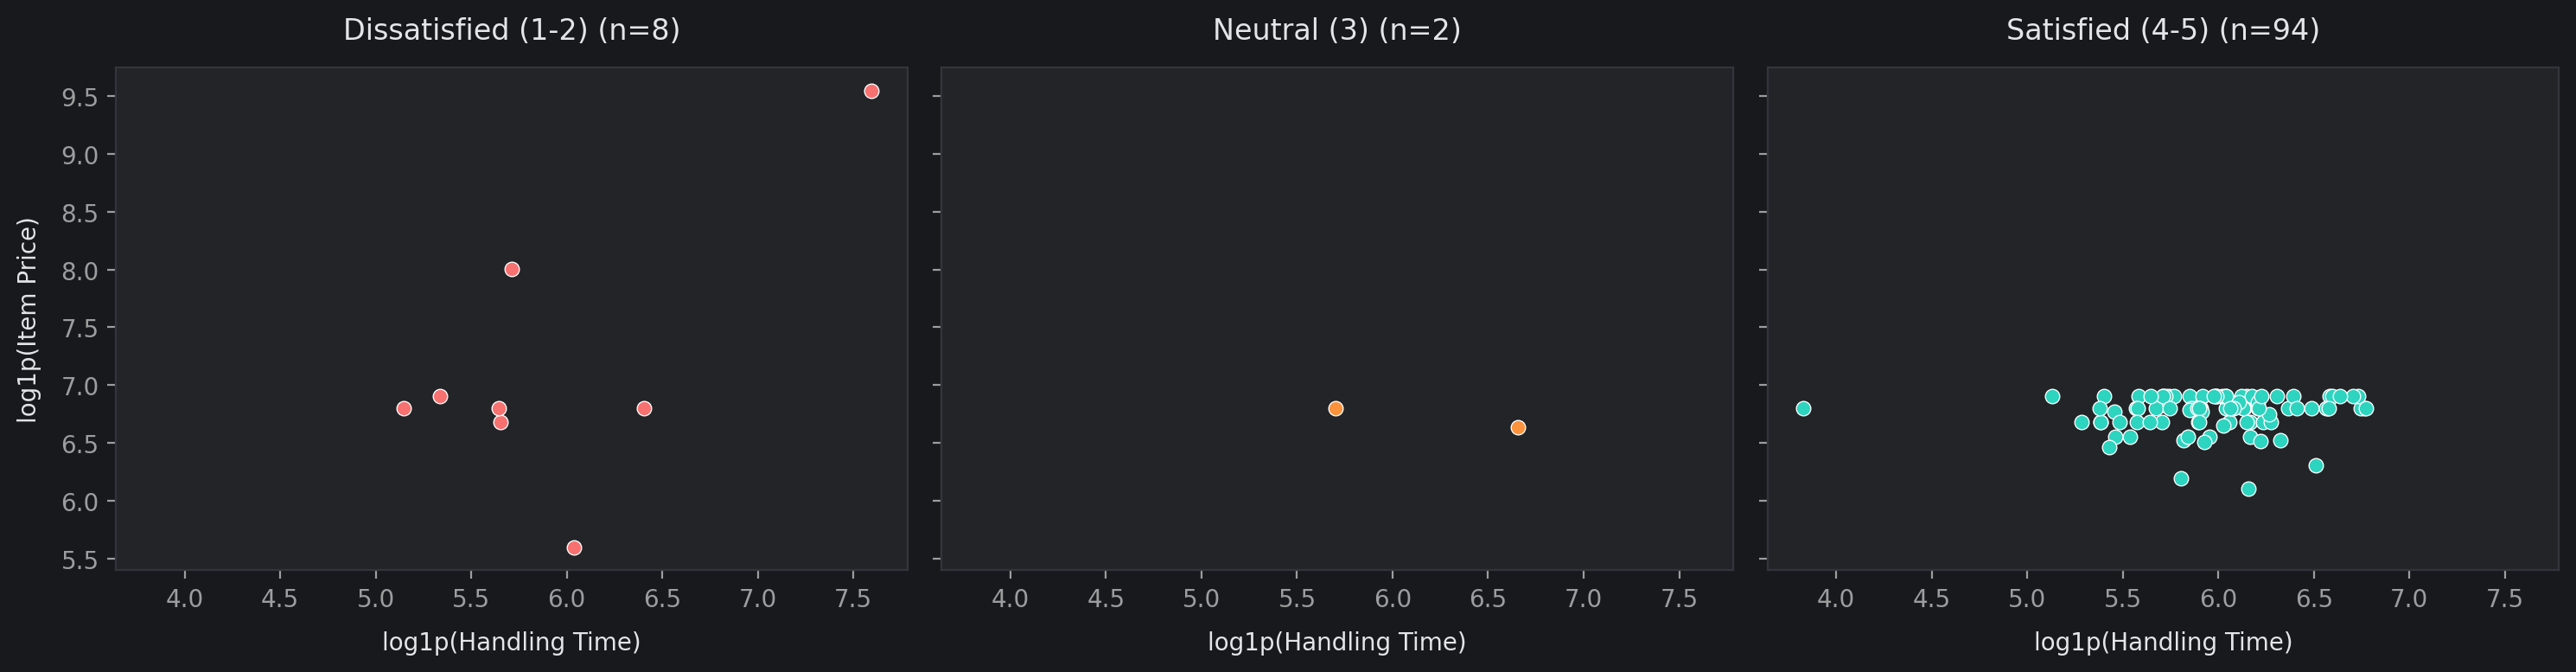

In [ ]:
# Chart 12: all tickets with both price and handling time recorded.
sample_scatter = eda_df.dropna(subset=['connected_handling_time', 'item_price']).copy()
sample_scatter['log_handling'] = np.log1p(sample_scatter['connected_handling_time'])
sample_scatter['log_price'] = np.log1p(sample_scatter['item_price'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, cohort in zip(axes, cohort_order):
    group = sample_scatter[sample_scatter['satisfaction_cohort'] == cohort]
    sns.scatterplot(data=group, x='log_handling', y='log_price', color=cohort_palette[cohort], ax=ax)
    ax.set_title(f'{cohort} (n={len(group)})')
    ax.set_xlabel('log1p(Handling Time)')
axes[0].set_ylabel('log1p(Item Price)')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Separate scatter plots show each satisfaction group on the same log1p axes. This keeps the larger satisfied group from covering the smaller groups. All tickets with both measurements are included, and each panel title gives its count.

##### 2. What is/are the insight(s) found from the chart?

* Only **104** tickets have both measurements: **8 dissatisfied**, **2 neutral**, **94 satisfied**. All **104** are shown.
* Most satisfied observations occupy a narrow price band; a few dissatisfied observations extend to higher prices and durations.
* Eight dissatisfied points and two neutral points cannot establish a stable high-friction cluster or a representative decision boundary.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

The chart highlights the need to improve joint telemetry coverage. Price/duration interactions are candidates for validation, but this small selected subset does not confirm their predictive value or justify operational routing rules.

#### Chart - 13: Mean CSAT by Issue Category & Agent Shift

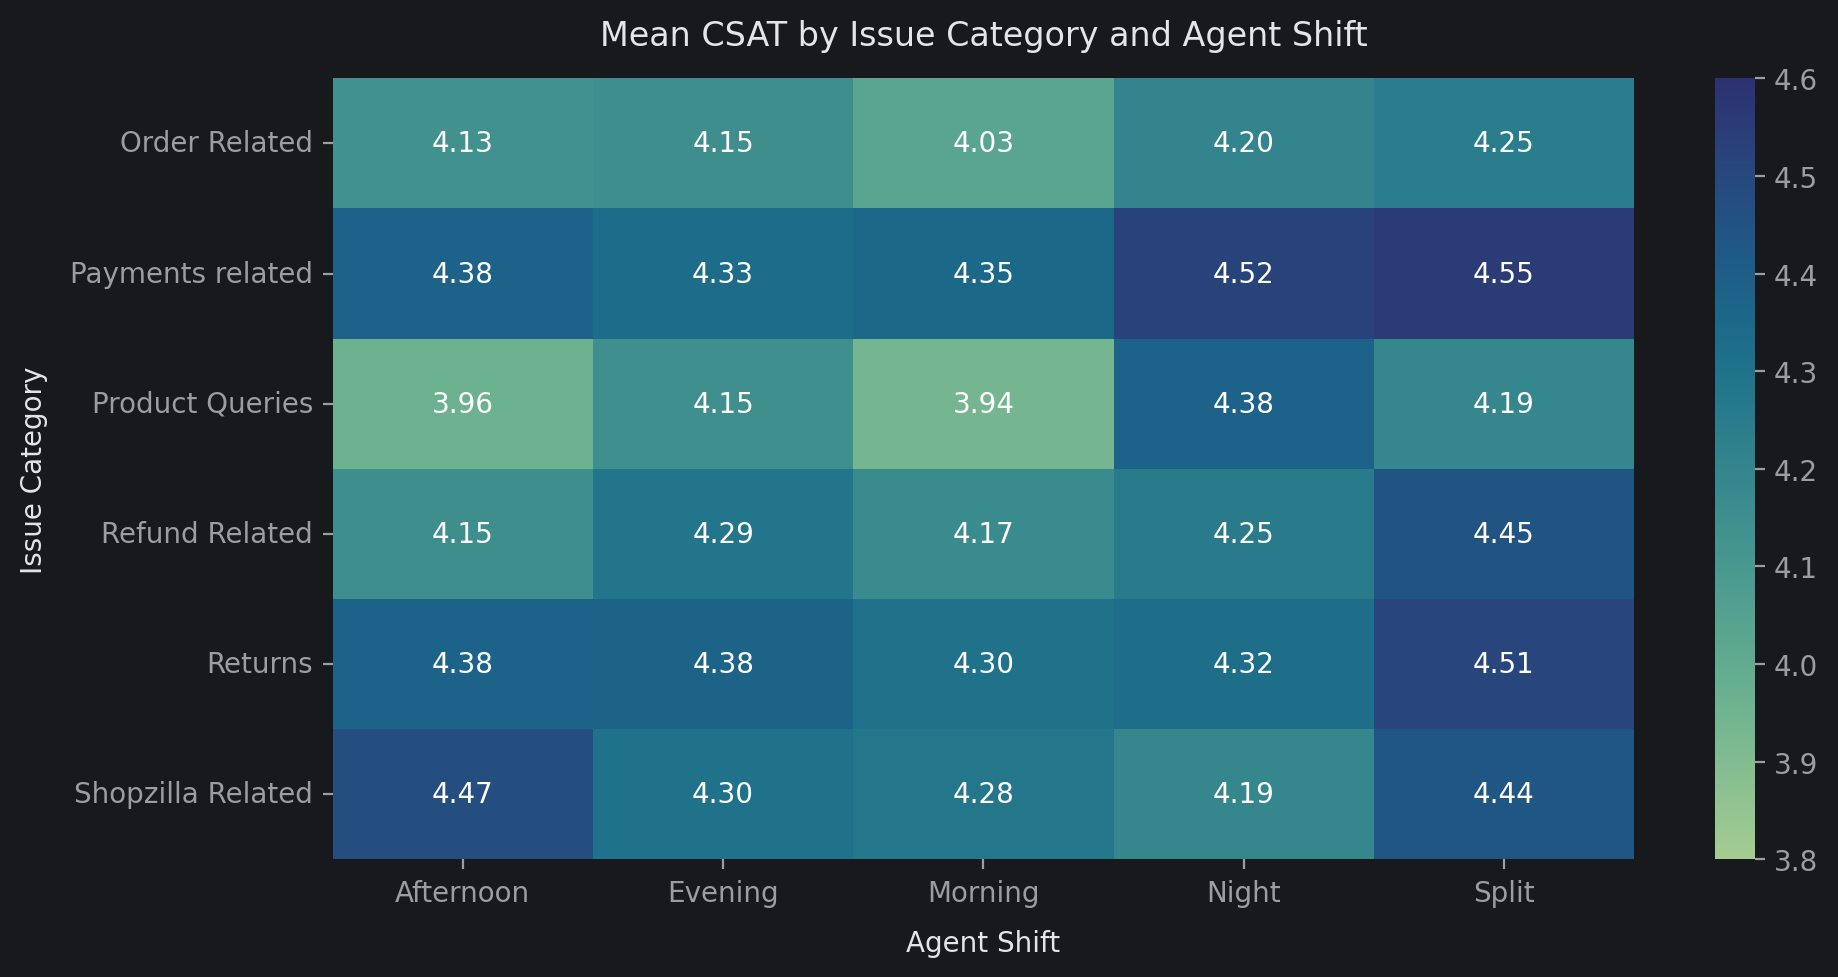

Ticket counts for each category and shift:


agent_shift,Afternoon,Evening,Morning,Night,Split
category,,,,,
Order Related,1258,9731,11113,342,771
Payments related,116,924,1156,21,110
Product Queries,187,1561,1801,50,93
Refund Related,329,1756,2201,76,188
Returns,3420,16638,21204,705,2130
Shopzilla Related,171,1056,1364,47,154


In [ ]:
# Chart 13: mean CSAT for the six largest categories across shifts.
category_data = eda_df[eda_df['category'].isin(top_cats)]
cat_shift_csat = category_data.pivot_table(index='category', columns='agent_shift', values='csat_score', aggfunc='mean')
cat_shift_counts = category_data.pivot_table(index='category', columns='agent_shift', values='csat_score', aggfunc='count')

plt.figure(figsize=(10, 5))
sns.heatmap(cat_shift_csat, annot=True, fmt='.2f', cmap='crest', vmin=3.8, vmax=4.6)
plt.title('Mean CSAT by Issue Category and Agent Shift')
plt.xlabel('Agent Shift')
plt.ylabel('Issue Category')
plt.tight_layout()
plt.show()
print('Ticket counts for each category and shift:')
display(cat_shift_counts)

##### 1. Why did you pick the specific chart?

A heatmap compares average CSAT for the same six issue categories used in Chart 10 across agent shifts. Its **3.8–4.6** scale matches Chart 11. The supporting table shows ticket counts so averages based on small groups can be identified.

##### 2. What is/are the insight(s) found from the chart?

* **Morning Product Queries: 3.937** is the lowest displayed category/shift mean; Afternoon Product Queries is **3.963**.
* **Split Payments related: 4.555** is the highest displayed mean.
* Returns ranges from **4.301 Morning** to **4.513 Split**; Evening Returns is **4.378**. The chart does not show a late-shift Returns collapse. Review the displayed counts before comparing cells.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Review Product Queries across morning/afternoon shifts and check issue complexity and staffing. Use counts and follow-up analysis before reallocating specialist staff; aggregate means cannot establish shift-related causes.

#### Chart - 14: Correlation Heatmap

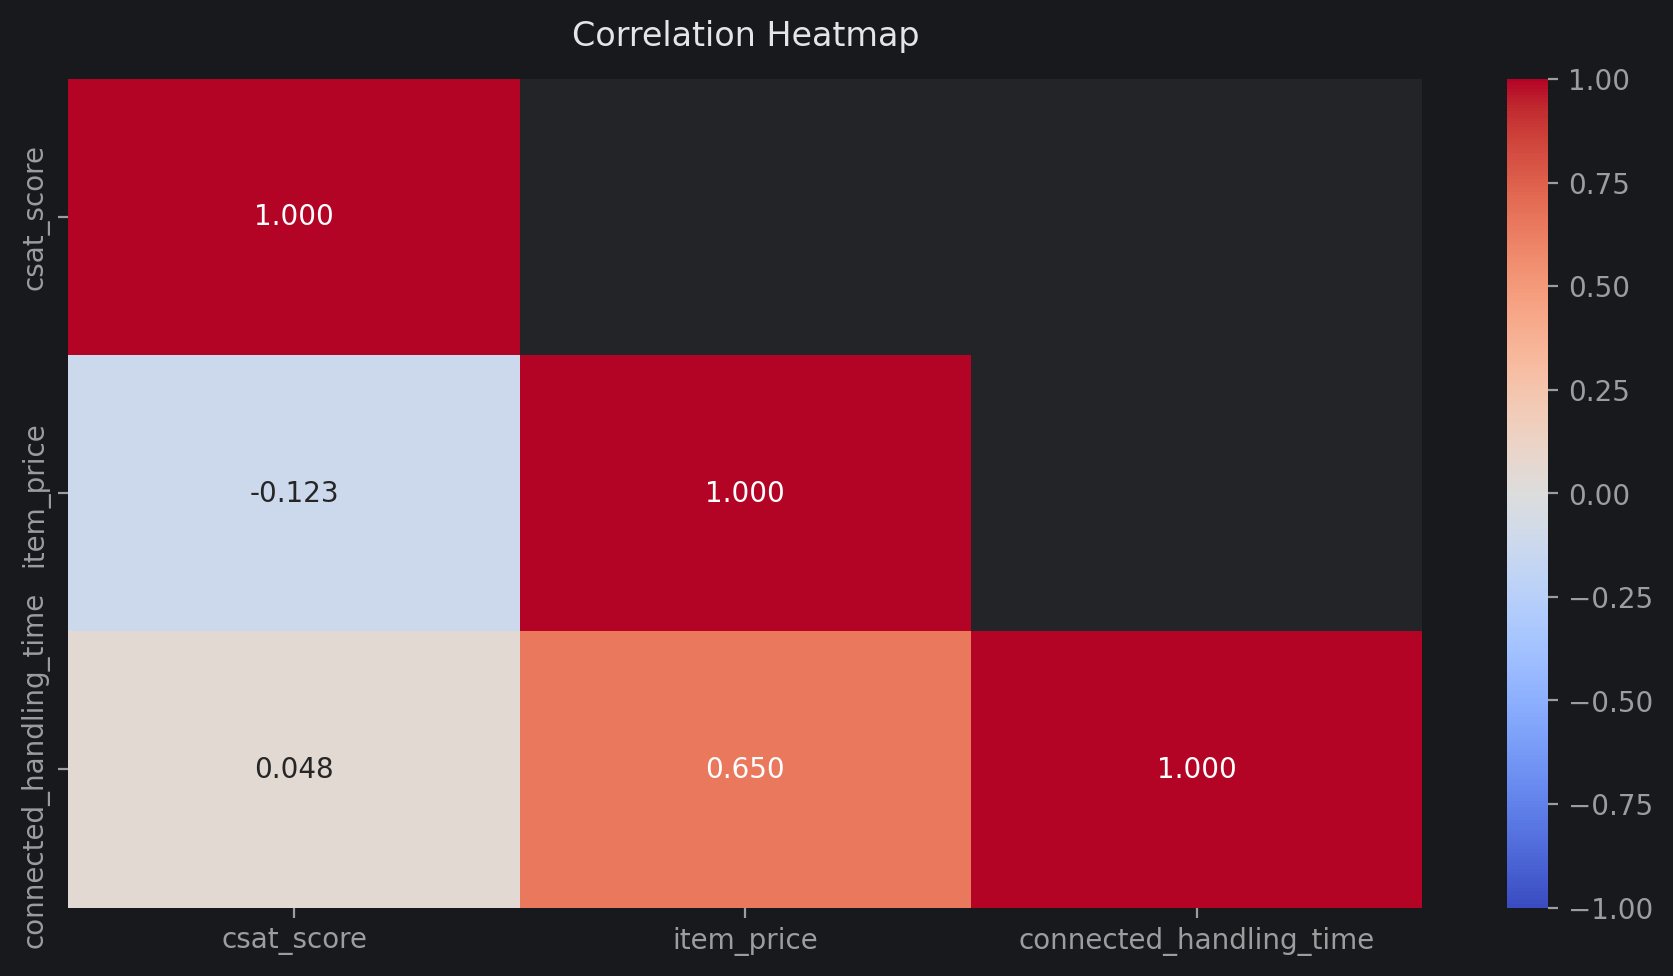

Number of recorded values used for each correlation:


,csat_score,item_price,connected_handling_time
csat_score,85907,17206,242
item_price,17206,17206,104
connected_handling_time,242,104,242


In [ ]:
# Chart 14: correlations using recorded values.
num_cols = ['csat_score', 'item_price', 'connected_handling_time']
corr_matrix = eda_df[num_cols].corr()
pair_counts = eda_df[num_cols].notna().astype(int).T.dot(eda_df[num_cols].notna().astype(int))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

plt.figure(figsize=(9, 5))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()
print('Number of recorded values used for each correlation:')
display(pair_counts)

##### 1. Why did you pick the specific chart?

A Pearson correlation heatmap shows the strength of linear relationships between the numerical variables. The lower triangle avoids repeating values, and the diagonal shows each variable's correlation with itself (**1.000**). The table below gives the number of recorded observations used for each pair.

##### 2. What is/are the insight(s) found from the chart?

* **Price vs CSAT:** r=**−0.123**, n=**17,206**; **handling vs CSAT:** r=**0.048**, n=**242**.
* **Price vs handling:** r=**0.650**, based on only **104** complete pairs. Thus, the predictors are not uniformly uncorrelated in the observed subset.
* Weak target correlations do not prove nonlinearity, ANN superiority or absence of useful linear models. Pairwise deletion and sparse coverage limit generalization.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Use these correlations as descriptive checks and compare candidate models on held-out data. Neither Pearson coefficients nor this selected 104-ticket subset establishes the best architecture, causal drivers or overall multicollinearity.

#### Chart - 15: Pair Plot

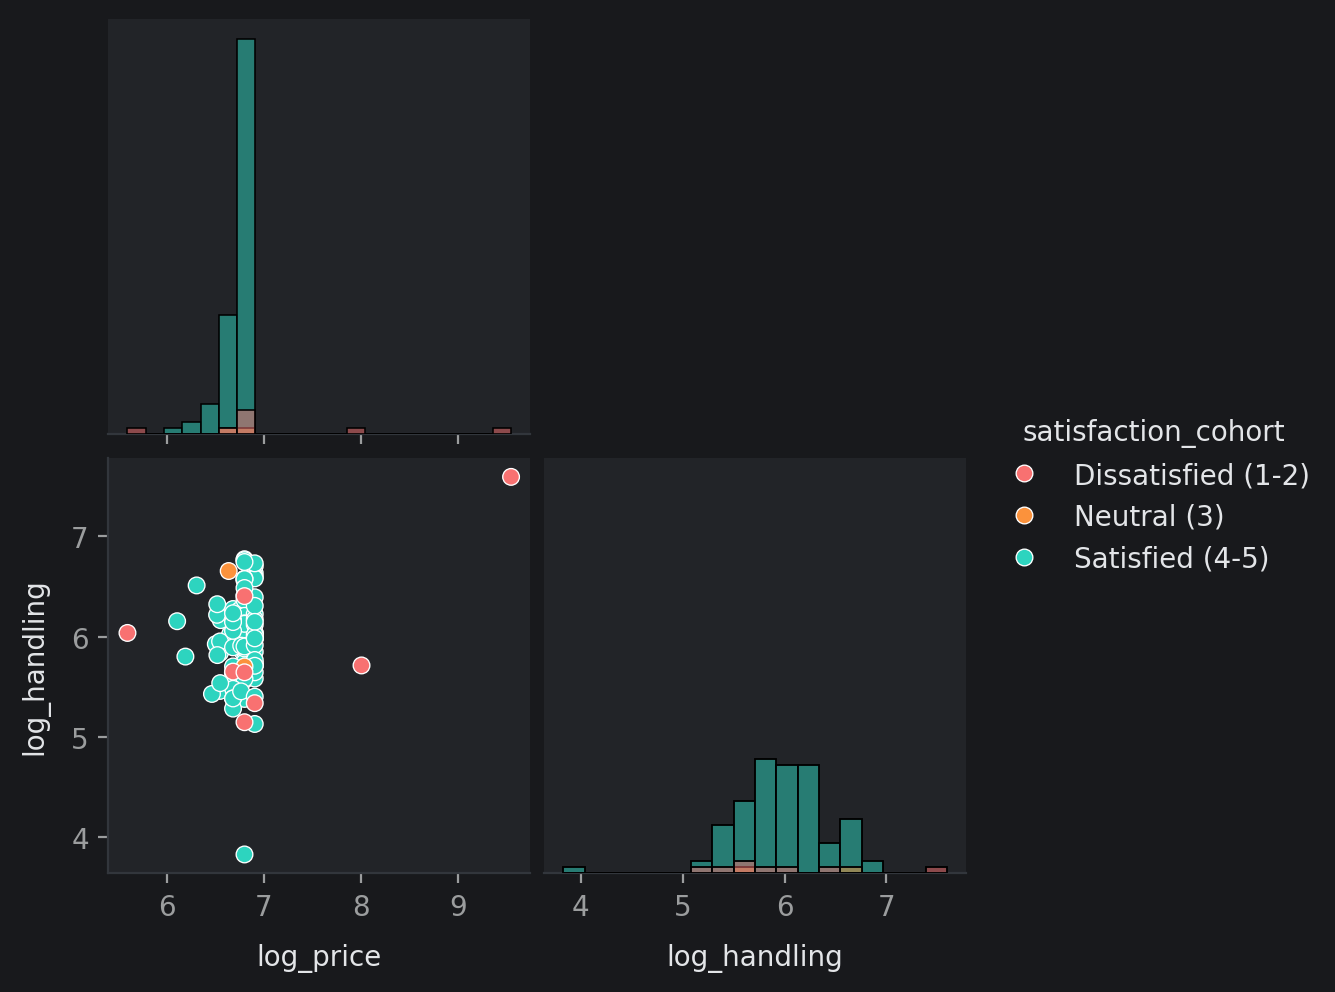

In [ ]:
# Chart 15: continuous features for all complete cases.
pairplot_sample = eda_df.dropna(subset=['item_price', 'connected_handling_time']).copy()
pairplot_sample = pairplot_sample.sort_values('satisfaction_cohort', ascending=False)
pairplot_sample['log_price'] = np.log1p(pairplot_sample['item_price'])
pairplot_sample['log_handling'] = np.log1p(pairplot_sample['connected_handling_time'])

sns.pairplot(pairplot_sample, vars=['log_price', 'log_handling'],
             hue='satisfaction_cohort', palette=cohort_palette, diag_kind='hist', corner=True)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot compares log1p price and handling time across the three satisfaction groups. Histogram diagonals show the distributions without fitting smooth curves to very small groups. CSAT defines the colors; it is not repeated as a numerical axis. The plot uses the same **104 complete cases** as Chart 12.

##### 2. What is/are the insight(s) found from the chart?

* The plot contains the same **104 complete cases** as Chart 12: **8 dissatisfied**, **2 neutral**, **94 satisfied**.
* Observed cohorts overlap in handling time and typical price ranges; a few high-price dissatisfied points extend the tail.
* The groups are not clearly separated. The histograms show counts within these **104 complete cases**, not the full dataset.

##### 3. Will the gained insights help creating a positive business impact?

Are there any insights that lead to negative growth? Justify with specific reason.

Use the plot to check overlap, tails and coverage before modeling. Better joint measurements and held-out evaluation are needed to assess feature utility. The visible patterns do not confirm separable ANN decision boundaries or improved business outcomes.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

This section checks three questions suggested by the EDA:
- **Hypothesis - 1**: Are observed item prices higher for customers who gave score 1 than score 5?
- **Hypothesis - 2**: Does average CSAT differ across agent experience groups?
- **Hypothesis - 3**: Is satisfaction related to the support channel?

We use a **5% significance level (p < 0.05)**. A small p-value suggests a relationship, but does not prove that one factor causes another. Price calculations use recorded prices only. The final table also checks that the conclusions still hold when testing all three questions together.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null hypothesis (H₀):** The average recorded item price for score-1 tickets is not higher than for score-5 tickets.
* **Alternative hypothesis (H₁):** The average recorded item price for score-1 tickets is higher than for score-5 tickets.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value
from scipy import stats

# Extract item prices for dissatisfied (CSAT = 1) and satisfied (CSAT = 5) cohorts
price_csat_1 = eda_df[eda_df['csat_score'] == 1]['item_price'].dropna()
price_csat_5 = eda_df[eda_df['csat_score'] == 5]['item_price'].dropna()

# Welch's Two-Sample t-test (unequal variances, right-tailed)
t_stat, p_val = stats.ttest_ind(price_csat_1, price_csat_5, equal_var=False, alternative='greater')

test_results = {'Observed price: CSAT 1 > 5': float(p_val)}
assert np.isfinite(t_stat) and 0 <= p_val <= 1

print("TEST 1: ORDER ITEM PRICE VS. SATISFACTION (WELCH'S T-TEST)")
print("=" * 60)
print(f"CSAT 1 Sample Size  : {len(price_csat_1):,} | Mean: {price_csat_1.mean():.2f} | Std: {price_csat_1.std():.2f}")
print(f"CSAT 5 Sample Size  : {len(price_csat_5):,} | Mean: {price_csat_5.mean():.2f} | Std: {price_csat_5.std():.2f}")
print(f"Welch's t-statistic : {t_stat:.4f}")
print(f"Calculated p-value  : {p_val:.4e}")

alpha = 0.05
if p_val < alpha:
    custom_display(f"Reject H0 at alpha = {alpha}.\nObserved prices are higher on average for exact CSAT 1 than CSAT 5; this is an association in the observed-price subset.")
else:
    custom_display(f"Fail to Reject H0 at alpha = {alpha}.")

TEST 1: ORDER ITEM PRICE VS. SATISFACTION (WELCH'S T-TEST)
CSAT 1 Sample Size  : 3,368 | Mean: 8848.80 | Std: 16126.78
CSAT 5 Sample Size  : 10,766 | Mean: 4713.35 | Std: 11315.07
Welch's t-statistic : 13.8534
Calculated p-value  : 4.6271e-43
┌───────────────────────────────────────────────────────────────────────┐
│  Reject H0 at alpha = 0.05.                                           │
│  Observed prices are higher on average for exact CSAT 1 than CSAT 5;  │
│  this is an association in the observed-price subset.                 │
└───────────────────────────────────────────────────────────────────────┘


##### Which statistical test have you done to obtain P-Value?

A **one-sided Welch's t-test** was used to compare the average item prices of the two groups.

##### Why did you choose the specific statistical test?

Welch's t-test is suitable because we are comparing two averages, and the groups have different sizes and price variation.

The average recorded price is **8,848.80 for score 1 (3,368 tickets)** and **4,713.35 for score 5 (10,766 tickets)**. The p-value is far below 0.05, so we reject H₀. Higher prices are associated with lower satisfaction in these two groups. This result applies to tickets with recorded prices and does not prove that higher prices cause dissatisfaction.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null hypothesis (H₀):** Average CSAT is the same across all five agent experience groups.
* **Alternative hypothesis (H₁):** At least one group has a different average CSAT.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value

# Filter groups across tenure cohorts
tenure_groups = [
    group['csat_score'].values
    for name, group in eda_df.groupby('tenure_bucket')
    if name != 'Unknown' and len(group) > 30
]

# One-Way ANOVA omnibus test
f_stat, p_val = stats.f_oneway(*tenure_groups)

test_results['Tenure means'] = float(p_val)
all_scores = np.concatenate(tenure_groups)
ss_between = sum(len(g) * (g.mean() - all_scores.mean()) ** 2 for g in tenure_groups)
eta_squared = ss_between / np.sum((all_scores - all_scores.mean()) ** 2)
assert np.isfinite(f_stat) and 0 <= p_val <= 1
print(f'Tenure eta squared: {eta_squared:.5f}\n')

print("TEST 2: AGENT TENURE VS CSAT SCORE (ONE-WAY ANOVA)")
print("=" * 60)
for name, group in eda_df.groupby('tenure_bucket'):
    if name != 'Unknown':
        print(f"Tenure [{name:15s}] : Mean CSAT = {group['csat_score'].mean():.3f} (n = {len(group):,})")

print(f"\nANOVA F-statistic   : {f_stat:.4f}")
print(f"Calculated p-value  : {p_val:.4e}")

alpha = 0.05
if p_val < alpha:
    custom_display(f"Reject H0 at alpha = {alpha}. At least one tenure cohort has a different mean CSAT; this does not establish causality.")
else:
    custom_display(f"Fail to Reject H0 at alpha = {alpha}.")

Tenure eta squared: 0.00233

TEST 2: AGENT TENURE VS CSAT SCORE (ONE-WAY ANOVA)
Tenure [0-30           ] : Mean CSAT = 4.259 (n = 11,318)
Tenure [31-60          ] : Mean CSAT = 4.296 (n = 11,665)
Tenure [61-90          ] : Mean CSAT = 4.347 (n = 6,741)
Tenure [>90            ] : Mean CSAT = 4.273 (n = 30,660)
Tenure [On Job Training] : Mean CSAT = 4.145 (n = 25,523)

ANOVA F-statistic   : 50.0622
Calculated p-value  : 3.7241e-42
┌─────────────────────────────────────────────────────────────────────────┐
│  Reject H0 at alpha = 0.05. At least one tenure cohort has a different  │
│  mean CSAT; this does not establish causality.                          │
└─────────────────────────────────────────────────────────────────────────┘


##### Which statistical test have you done to obtain P-Value?

A **one-way ANOVA** was used to compare average CSAT across the five agent experience groups.

##### Why did you choose the specific statistical test?

ANOVA compares the averages of more than two groups in one test.

Here, **F = 50.0622** and the p-value is below 0.05, so we reject H₀. Average CSAT differs across the experience groups. However, the differences are small: experience groups explain only about **0.23%** of the variation in scores. The test does not tell us which pairs of groups differ or prove that experience causes better ratings.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null hypothesis (H₀):** Satisfaction is unrelated to the support channel.
* **Alternative hypothesis (H₁):** Satisfaction is related to the support channel.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value

# Create binary satisfaction flag: Dissatisfied (CSAT <= 2) vs Satisfied (CSAT >= 4)
df_valid_csat = eda_df[eda_df['csat_score'] != 3].copy()
df_valid_csat['satisfaction_binary'] = df_valid_csat['csat_score'].apply(
    lambda x: 'Satisfied (4-5)' if x >= 4 else 'Dissatisfied (1-2)'
)

# Build contingency table
contingency_table = pd.crosstab(df_valid_csat['channel_name'], df_valid_csat['satisfaction_binary'])
chi2_stat, p_val, dof, expected = stats.chi2_contingency(contingency_table)

print("TEST 3: SUPPORT CHANNEL VS SATISFACTION (CHI-SQUARE TEST)")
print("=" * 60)
print("Observed Contingency Table:")
display(contingency_table)

print(f"\nChi-Square Statistic : {chi2_stat:.4f}")
print(f"Calculated p-value   : {p_val:.4e}")
print(f"Degrees of Freedom   : {dof}")

alpha = 0.05
if p_val < alpha:
    custom_display(f"Reject H0 at alpha = {alpha}. Customer satisfaction is significantly dependent on channel.")
else:
    custom_display(f"Fail to Reject H0 at alpha = {alpha}.")

TEST 3: SUPPORT CHANNEL VS SATISFACTION (CHI-SQUARE TEST)
Observed Contingency Table:


satisfaction_binary,Dissatisfied (1-2),Satisfied (4-5)
channel_name,,
Email,700,2221
Inbound,9756,56353
Outcall,2057,12262



Chi-Square Statistic : 191.5305
Calculated p-value   : 2.5685e-42
Degrees of Freedom   : 2
┌─────────────────────────────────────────────────────────────────────┐
│  Reject H0 at alpha = 0.05. Customer satisfaction is significantly  │
│  dependent on channel.                                              │
└─────────────────────────────────────────────────────────────────────┘


##### Which statistical test have you done to obtain P-Value?

A **chi-square test of independence** was used to check the relationship between support channel and satisfaction group.

##### Why did you choose the specific statistical test?

The chi-square test is suitable because both variables are categories.

We compare **Dissatisfied (scores 1–2)** with **Satisfied (scores 4–5)**. Score 3 is excluded, leaving **83,349 tickets**. The test gives **χ² = 191.5305** and a p-value below 0.05, so we reject H₀. Channel and satisfaction are related, but the relationship is weak. This does not prove that switching channels will improve satisfaction.

## ***6. Feature Engineering & Data Pre-processing***

### Handling Missing Values

In [ ]:
# Prepare the modeling dataset from the observed-data copy.
df = eda_df.drop(columns=['satisfaction_cohort', 'unique_id', 'order_id', 'agent_name', 'supervisor', 'manager'],
                 errors='ignore').copy(deep=True)
for col in ['item_price', 'connected_handling_time']:
    df[col] = df[col].fillna(df[col].median())
    q25, q75 = df[col].quantile([.25, .75])
    df[col] = df[col].clip(lower=0, upper=q75 + 2.5 * (q75 - q25))
df['order_to_issue_days'] = (df['issue_reported_at'] - df['order_date_time']).dt.total_seconds() / 86400
df['order_to_issue_days'] = df['order_to_issue_days'].fillna(0).clip(lower=0)
print(f'Modeling dataset: {len(df):,} rows')
print('Numerical imputation and outlier capping complete.')


Modeling dataset: 85,907 rows
Numerical imputation and outlier capping complete.


In [ ]:
# Audit remaining nulls across active attributes
null_counts = df.isnull().sum()
remaining_nulls = null_counts[null_counts > 0]

print("--- Missing Values Summary ---")
display(remaining_nulls)

--- Missing Values Summary ---


,0
order_date_time,68693


#### What all missing value imputation techniques have you used and why did you use those techniques?

Missing prices and handling times are filled with the dataset medians: **979 for price** and **427 for handling time**. Missing text and categories use the placeholders prepared during data wrangling. The EDA data remains separate, so its plots still show recorded measurements.

### Handling Outliers

In [ ]:
# Summarize numerical values after imputation and IQR-based capping.
print("--- Outlier Summary ---")
for col in ['connected_handling_time', 'item_price']:
    q25 = df[col].quantile(0.25)
    q75 = df[col].quantile(0.75)
    iqr = q75 - q25
    upper_fence = q75 + (2.5 * iqr)
    outliers_above_fence = (df[col] > upper_fence).sum()
    print(f"Feature: {col:25s} | Max: {df[col].max():8.2f} | Upper Fence: {upper_fence:8.2f} | Outliers Beyond Fence: {outliers_above_fence}")

--- Outlier Summary ---
Feature: connected_handling_time   | Max:   427.00 | Upper Fence:   427.00 | Outliers Beyond Fence: 0
Feature: item_price                | Max:   979.00 | Upper Fence:   979.00 | Outliers Beyond Fence: 0


##### What all outlier treatment techniques have you used and why did you use those techniques?

Applied IQR-based capping after filling missing values. The upper limits are **979 for price** and **427 for handling time**. Because many measurements are missing, filling them first concentrates the values around these medians. The EDA plots use recorded measurements before this treatment.

### Categorical Encoding

In [ ]:
# Inspect categories here; encode them once in the splitting cell below.
categorical_cols = ['channel_name', 'category', 'product_category', 'tenure_bucket', 'agent_shift']
for col in categorical_cols:
    print(f'{col}: {df[col].nunique()} categories')

channel_name: 3 categories
category: 12 categories
product_category: 10 categories
tenure_bucket: 5 categories
agent_shift: 5 categories


#### What all categorical encoding techniques have you used & why did you use those techniques?

Used **one-hot encoding** with `pd.get_dummies` to turn channel, category, product group, tenure and shift into numerical 0/1 columns. Encoding happens once, before splitting. The first level of each category is dropped to avoid redundant columns.

### Text Preprocessing

#### Text Sanitization

In [ ]:
# Text Sanitization Function
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['cleaned_remarks'] = df['customer_remarks'].apply(clean_text)

#### NLP Behavioral Proxies

In [ ]:
# Extract NLP Behavioral Proxies
df['remark_char_length'] = df['customer_remarks'].astype(str).str.len()
df['remark_word_count'] = df['customer_remarks'].astype(str).str.split().str.len()

# Domain Negative Trigger Lexicon
negative_triggers = [
    'delay', 'damaged', 'worst', 'poor', 'broken',
    'refund', 'never', 'cancel', 'horrible', 'cheat', 'fake'
]
regex_neg = r'\b(' + '|'.join(negative_triggers) + r')\b'
df['has_negative_keywords'] = df['cleaned_remarks'].str.contains(regex_neg, regex=True).astype(int)

#### Text Vectorization

In [ ]:
# Sparse TF-IDF Vectorization (Top 100 n-grams)
tfidf = TfidfVectorizer(
    max_features=100,
    stop_words='english',
    ngram_range=(1, 2)
)
tfidf_matrix = tfidf.fit_transform(df['cleaned_remarks'])
tfidf_cols = [f"tfidf_{w}" for w in tfidf.get_feature_names_out()]
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_cols, index=df.index)

print(f"Extracted {len(tfidf_cols)} TF-IDF n-gram text features.")

Extracted 100 TF-IDF n-gram text features.


#### Text Processing Techniques

Customer remarks are converted into numerical features through:
* Lowercasing and punctuation removal.
* Character and word counts.
* Complaint-related keyword flags.
* **100 TF-IDF features** from individual words and word pairs.

TF-IDF assigns numerical weights to words so the neural networks can use text. The vocabulary is created before the data split; this is a limitation of the preprocessing approach.

### Feature Engineering and Selection

#### 1. Feature Manipulation

In [ ]:
# Manipulate Features to minimize feature correlation and create new features

# Feature Manipulation: Operational Latencies & Cyclical Time
# First-response SLA turnaround in hours
df['response_time_hours'] = (
    df['issue_responded'] - df['issue_reported_at']
).dt.total_seconds() / 3600.0

# Order-to-complaint lag in days
df['order_to_issue_days'] = (
    df['issue_reported_at'] - df['order_date_time']
).dt.total_seconds() / 86400.0

# Survey submission turnaround in hours
df['survey_lag_hours'] = (
    df['survey_response_date'] - df['issue_responded']
).dt.total_seconds() / 3600.0

# Clean and clip negative timestamp anomalies
for lat_col in ['response_time_hours', 'order_to_issue_days', 'survey_lag_hours']:
    df[lat_col] = df[lat_col].fillna(df[lat_col].median()).clip(lower=0.0)

# Cyclical 24-hour trigonometric transformation
df['issue_hour'] = df['issue_reported_at'].dt.hour.fillna(12).astype(int)
df['issue_hour_sin'] = np.sin(2 * np.pi * df['issue_hour'] / 24.0)
df['issue_hour_cos'] = np.cos(2 * np.pi * df['issue_hour'] / 24.0)
df['is_weekend'] = df['issue_reported_at'].dt.dayofweek.isin([5, 6]).astype(int)

# Composite operational friction index
df['handling_to_price_ratio'] = (df['connected_handling_time'] + 1.0) / np.log1p(df['item_price'] + 1.0)

#### 2. Feature Selection

In [ ]:
# Select your features wisely to avoid overfitting

# Feature Selection & Merging
# Combine structured features with TF-IDF textual features
df_combined = pd.concat([df, tfidf_df], axis=1)

# Drop raw timestamps, processed text strings, and uninformative database identifiers
cols_to_prune = [
    'order_date_time',
    'issue_reported_at',
    'issue_responded',
    'survey_response_date',
    'customer_remarks',
    'cleaned_remarks',
    'customer_city',      # High-cardinality nominal variable (>1,000 unique values)
    'sub_category',       # High cardinality; subsumed by primary category
    'issue_hour'          # Retained via cyclical sine and cosine features
]

df_selected = df_combined.drop(columns=[col for col in cols_to_prune if col in df_combined.columns])

print("Feature Manipulation & Selection complete.")
print(f"Matrix Dimensions: {df_selected.shape[0]:,} rows, {df_selected.shape[1]} columns")

Feature Manipulation & Selection complete.
Matrix Dimensions: 85,907 rows, 118 columns


##### What all feature selection methods have you used  and why?

* Created response delay, order-to-issue delay and survey turnaround from timestamps.
* Added time-of-day, weekend and handling-time/price features.
* Combined these features with one-hot categories, remark length, keyword flags and TF-IDF.
* Removed identifiers, raw text, raw timestamps and selected high-cardinality columns before training.

##### Which all features you found important and why?

The model can use **customer remarks, response delay, support channel, agent tenure, price and handling time**. The EDA suggests these may be useful, but does not prove their importance. Section 7 shows which features the trained ANN relies on using permutation importance.

### Data Transformation

In [ ]:
# Logarithmic transformation on heavily right-skewed numerical predictors
skewed_cols = ['item_price', 'connected_handling_time', 'response_time_hours']

print("--- Skewness Diagnostics Before vs After Log1p Transform ---")
for col in skewed_cols:
    skew_raw = df_selected[col].skew()
    log_transformed = np.log1p(df_selected[col])
    skew_log = log_transformed.skew()
    print(f"Feature: {col:25s} | Raw Skew: {skew_raw:6.2f} | Log1p Skew: {skew_log:6.2f}")
    df_selected[f'log_{col}'] = log_transformed

# Drop original un-transformed skewed continuous columns
df_selected = df_selected.drop(columns=skewed_cols)

--- Skewness Diagnostics Before vs After Log1p Transform ---
Feature: item_price                | Raw Skew:  -3.36 | Log1p Skew:  -5.22
Feature: connected_handling_time   | Raw Skew: -38.27 | Log1p Skew: -114.06
Feature: response_time_hours       | Raw Skew:   5.32 | Log1p Skew:   2.22


#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Applied **log1p**, meaning log(1 + value), to price, handling time and response delay. This compresses large values and works with zeros. The printed table compares skewness before and after transformation. The original columns are then replaced by their log-transformed versions.

### Data Scaling

In [ ]:
# Scaling your data - (Should be done post data splitting)

##### Which method have you used to scale you data and why?

The models use log-transformed numerical features, 0/1 category columns and TF-IDF features. **No additional scaling is applied before training.** The scaler in the export section is separate from the training process.

### Dimensionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No PCA was used. The notebook keeps the engineered features and limits TF-IDF to **100 features**, which keeps the feature set manageable and the feature names understandable.

### Data Splitting

In [ ]:
# Split your data to train and test. Choose Splitting ratio wisely.

# Drop Leaked and Non-Feature Columns
if 'satisfaction_cohort' in df_selected.columns:
    df_selected = df_selected.drop(columns=['satisfaction_cohort'])

# Encode the categorical columns into numeric 0/1 dummies
cat_cols = ['channel_name', 'category', 'product_category', 'tenure_bucket', 'agent_shift']
df_encoded = pd.get_dummies(df_selected, columns=cat_cols, drop_first=True, dtype=float)

# Separate features X and zero-indexed target y
X = df_encoded.drop(columns=['csat_score'])
y = (df_encoded['csat_score'] - 1).astype(int)

# Stratified 70% Train, 15% Validation, 15% Holdout Test Split
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.1765,  # 0.1765 of 85% ≈ 15% of total dataset
    random_state=SEED,
    stratify=y_train_full
)

custom_display("DATA SPLITTING AUDIT (STRATIFIED 70/15/15)", content=[
    f"Feature Set           : {X_train.shape[1]} columns",
    f"Training Partition    : {X_train.shape[0]:,} samples ({X_train.shape[0]/len(df)*100:.1f}%)",
    f"Validation Partition  : {X_val.shape[0]:,} samples ({X_val.shape[0]/len(df)*100:.1f}%)",
    f"Holdout Test Partition: {X_test.shape[0]:,} samples ({X_test.shape[0]/len(df)*100:.1f}%)"
])

assert not (set(X_train.index) & set(X_val.index) or set(X_train.index) & set(X_test.index) or set(X_val.index) & set(X_test.index))
assert X_train.columns.equals(X_val.columns) and X_train.columns.equals(X_test.columns)
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_val.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()

print(f'Checked non-overlapping splits and {X_train.shape[1]} numeric features.')


┌──────────────────────────────────────────────────┐
│    DATA SPLITTING AUDIT (STRATIFIED 70/15/15)    │
├──────────────────────────────────────────────────┤
│  Feature Set           : 142 columns             │
│  Training Partition    : 60,131 samples (70.0%)  │
│  Validation Partition  : 12,889 samples (15.0%)  │
│  Holdout Test Partition: 12,887 samples (15.0%)  │
└──────────────────────────────────────────────────┘
Checked non-overlapping splits and 142 numeric features.


##### What data splitting ratio have you used and why?

The data is split into approximately **70% training, 15% validation and 15% test**, with stratification and random seed **47**:
* **Training:** 60,131 tickets.
* **Validation:** 12,889 tickets.
* **Test:** 12,887 tickets.

Both models use the same partitions. Section 7 reports validation results; the test partition is kept separate.

### Handling Class Imbalance

##### Do you think the dataset is imbalanced? Explain Why.

Yes. **Score 5 represents 69.4%** of the 85,907 tickets. Scores 1 and 4 each represent **13.1%**, while scores 2 and 3 represent only **1.5%** and **3.0%**.

A model can get high accuracy by predicting score 5 most of the time. We therefore also check **macro F1**, which gives each rating equal importance, and **recall**, which shows how many actual examples of a rating the model identifies.

In [ ]:
# Handling Imbalanced Dataset (If needed)
# Calculate balanced class weights for multi-class cross-entropy loss
unique_classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight='balanced',
    classes=unique_classes,
    y=y_train
)

class_weight_dict = dict(zip(unique_classes, weights))

print("BALANCED CLASS WEIGHTS (FOR LOSS FUNCTION)")
print("=" * 42)
for cls_idx, weight_val in class_weight_dict.items():
    raw_rating = cls_idx + 1
    class_count = (y_train == cls_idx).sum()
    print(f"Class {cls_idx} (Rating {raw_rating}) | Count: {class_count:6,} | Assigned Penalty Weight: {weight_val:.4f}")


BALANCED CLASS WEIGHTS (FOR LOSS FUNCTION)
Class 0 (Rating 1) | Count:  7,860 | Assigned Penalty Weight: 1.5301
Class 1 (Rating 2) | Count:    899 | Assigned Penalty Weight: 13.3773
Class 2 (Rating 3) | Count:  1,790 | Assigned Penalty Weight: 6.7185
Class 3 (Rating 4) | Count:  7,853 | Assigned Penalty Weight: 1.5314
Class 4 (Rating 5) | Count: 41,729 | Assigned Penalty Weight: 0.2882


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

Used **class weights** for the ANN. Errors on less common ratings receive a larger penalty during training. The weights are calculated from training labels only.

This helps the model pay attention to rare ratings, but can also increase incorrect minority-class predictions. We check the results rather than assuming that weighting always improves performance.

## ***7. ML Model Implementation***

Two neural networks are compared: a basic MLP and a deeper ANN with class weights. The **142 input features** include text, support details and timing information.

The comparison uses **validation accuracy, macro F1 and CSAT-1 recall**. Macro F1 gives each rating equal importance, while CSAT-1 recall shows how many score-1 tickets are correctly identified.

**Limitation:** Survey timing and customer feedback may be collected with the rating, and some preprocessing is performed before splitting. These results describe classification of rated interactions; performance before survey collection needs separate evaluation.

* **Model 1:** Scikit-learn MLPClassifier with two hidden layers.
* **Model 2:** TensorFlow/Keras ANN with class weights, Batch Normalization and Dropout.

### ML Model - 1: Baseline Neural Network (MLPClassifier)

In [ ]:
X_train.columns

Index(['order_to_issue_days', 'remark_char_length', 'remark_word_count',
       'has_negative_keywords', 'survey_lag_hours', 'issue_hour_sin',
       'issue_hour_cos', 'is_weekend', 'handling_to_price_ratio',
       'tfidf_agent',
       ...
       'product_category_LifeStyle', 'product_category_Mobile',
       'tenure_bucket_31-60', 'tenure_bucket_61-90', 'tenure_bucket_>90',
       'tenure_bucket_On Job Training', 'agent_shift_Evening',
       'agent_shift_Morning', 'agent_shift_Night', 'agent_shift_Split'],
      dtype='object', length=142)

In [ ]:
# ML Model - 1: Baseline Neural Network (MLPClassifier)

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score

# 1. Initialize Baseline MLP
baseline_mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=30,
    random_state=SEED,
    early_stopping=True,
    validation_fraction=0.15
)

# 2. Fit on Training Data
print("Training ML Model - 1 (Baseline MLPClassifier)...")
baseline_mlp.fit(X_train, y_train)

# 3. Evaluate on Validation Set
val_preds_baseline = baseline_mlp.predict(X_val)

print("=" * 60)
print("ML MODEL - 1: BASELINE EVALUATION METRICS (VALIDATION SET)")
print("=" * 60)
print(f"Validation Accuracy : {accuracy_score(y_val, val_preds_baseline):.4f}")
print(f"Validation Macro F1 : {f1_score(y_val, val_preds_baseline, average='macro'):.4f}")
print("\nClassification Report:")
print(classification_report(y_val, val_preds_baseline, target_names=[f"CSAT {i}" for i in range(1, 6)], digits=4, zero_division=0))

Training ML Model - 1 (Baseline MLPClassifier)...
ML MODEL - 1: BASELINE EVALUATION METRICS (VALIDATION SET)
Validation Accuracy : 0.7176
Validation Macro F1 : 0.2405

Classification Report:
              precision    recall  f1-score   support

      CSAT 1     0.6426    0.2593    0.3696      1685
      CSAT 2     0.0000    0.0000    0.0000       192
      CSAT 3     0.0000    0.0000    0.0000       384
      CSAT 4     0.0000    0.0000    0.0000      1683
      CSAT 5     0.7218    0.9851    0.8331      8945

    accuracy                         0.7176     12889
   macro avg     0.2729    0.2489    0.2405     12889
weighted avg     0.5849    0.7176    0.6265     12889



### Validation Metrics & Confusion Matrix

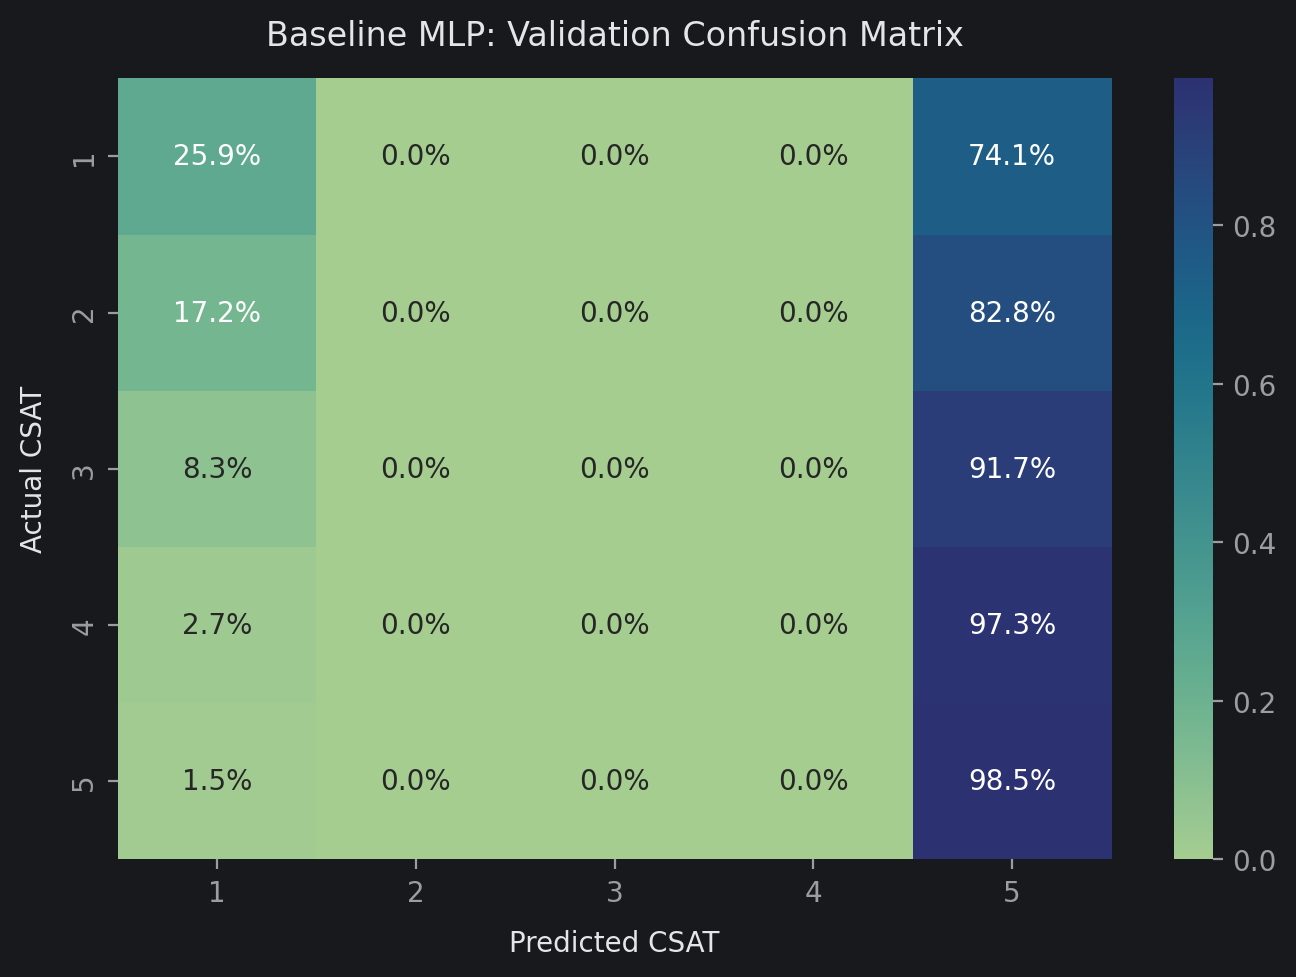

In [ ]:
# Baseline model: normalized confusion matrix.
cm_baseline = confusion_matrix(y_val, val_preds_baseline, normalize='true')

plt.figure(figsize=(7, 5))
sns.heatmap(cm_baseline, annot=True, fmt='.1%', cmap='crest',
            xticklabels=range(1, 6), yticklabels=range(1, 6))
plt.title('Baseline MLP: Validation Confusion Matrix')
plt.xlabel('Predicted CSAT')
plt.ylabel('Actual CSAT')
plt.tight_layout()
plt.show()

The baseline MLP has hidden layers with **64 and 32 neurons**.

On **12,889 validation tickets**, it achieved **71.76% accuracy**, **0.2405 macro F1** and **25.93% CSAT-1 recall**. It has zero recall for scores 2, 3 and 4, and predicts score 5 for most tickets. This shows why accuracy alone is not enough for this imbalanced dataset.

### ML Model - 2: Final Deep Learning ANN (Keras Sequential)

In [ ]:
# ML Model - 2: Final Deep Learning ANN (Keras Sequential)
import tensorflow as tf
tf.keras.utils.set_random_seed(SEED)
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# 1. Build Deep Feedforward Architecture
def build_csat_champion_ann(input_dim, num_classes=5):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),

        # Dense Block 1
        layers.Dense(256, kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.1),
        layers.Dropout(0.30),

        # Dense Block 2
        layers.Dense(128, kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.1),
        layers.Dropout(0.25),

        # Dense Block 3
        layers.Dense(64, kernel_initializer='he_normal'),
        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.1),
        layers.Dropout(0.15),

        # Output Multi-Class Softmax Layer
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

champion_ann = build_csat_champion_ann(input_dim=X_train.shape[1], num_classes=5)

# 2. Compile Model with Adam Optimizer and Sparse Categorical Crossentropy
champion_ann.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Setup Production Callbacks
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

# 4. Train Model with Balanced Class Weights
print("Training ML Model - 2 (Deep Learning Keras ANN)...")
history = champion_ann.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=2
)

Training ML Model - 2 (Deep Learning Keras ANN)...
Epoch 1/40
470/470 - 9s - 19ms/step - accuracy: 0.3021 - loss: 1.7337 - val_accuracy: 0.1421 - val_loss: 1.7440 - learning_rate: 0.0010
Epoch 2/40
470/470 - 3s - 6ms/step - accuracy: 0.3077 - loss: 1.6407 - val_accuracy: 0.1347 - val_loss: 1.9235 - learning_rate: 0.0010
Epoch 3/40
470/470 - 3s - 6ms/step - accuracy: 0.3344 - loss: 1.6088 - val_accuracy: 0.2721 - val_loss: 1.6331 - learning_rate: 0.0010
Epoch 4/40
470/470 - 5s - 10ms/step - accuracy: 0.3471 - loss: 1.5892 - val_accuracy: 0.2553 - val_loss: 1.7286 - learning_rate: 0.0010
Epoch 5/40
470/470 - 3s - 7ms/step - accuracy: 0.3579 - loss: 1.5811 - val_accuracy: 0.1532 - val_loss: 1.8601 - learning_rate: 0.0010
Epoch 6/40

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
470/470 - 3s - 6ms/step - accuracy: 0.3603 - loss: 1.5715 - val_accuracy: 0.2095 - val_loss: 1.8203 - learning_rate: 0.0010
Epoch 7/40
470/470 - 3s - 6ms/step - accuracy: 0.3703 - loss

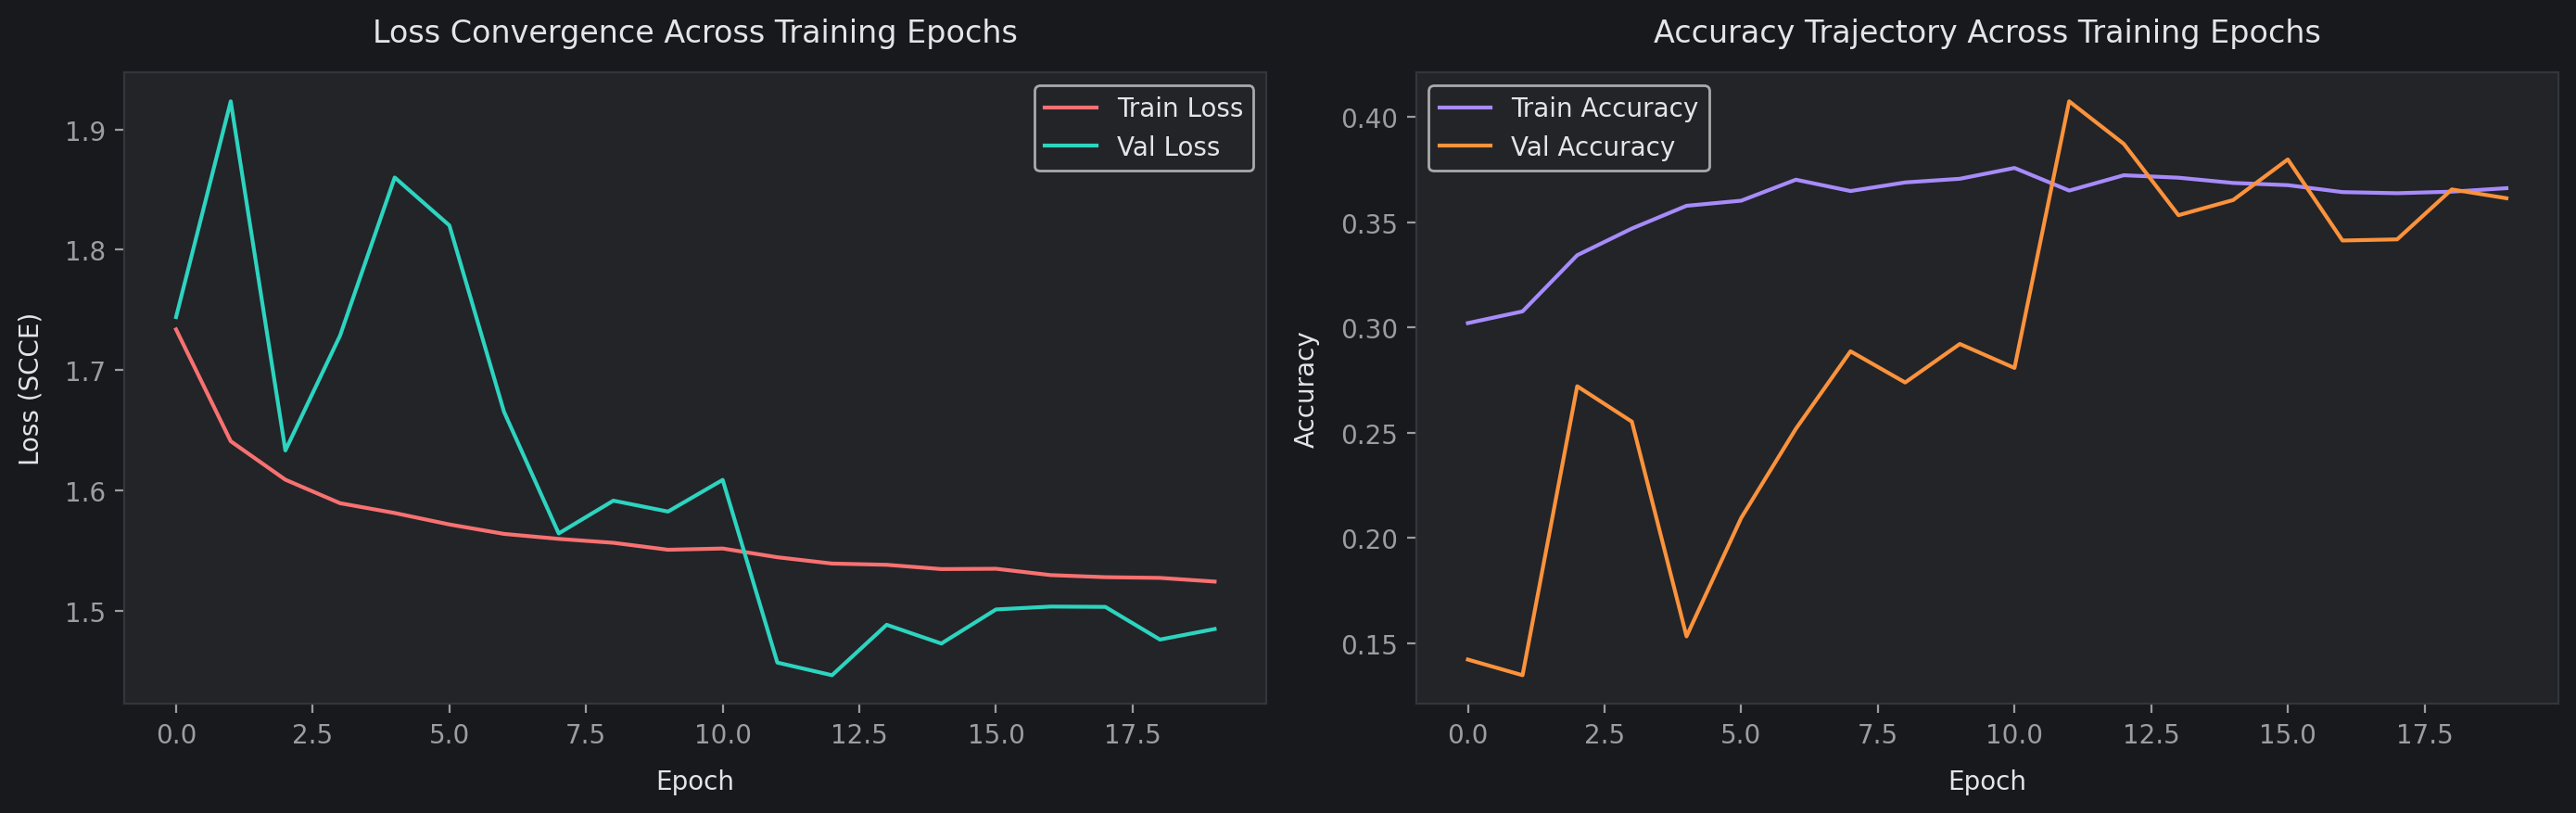

ML MODEL - 2: CHAMPION ANN EVALUATION METRICS (VALIDATION SET)
Validation Accuracy : 0.3873
Validation Macro F1 : 0.2532

Classification Report:
              precision    recall  f1-score   support

      CSAT 1     0.4264    0.4451    0.4355      1685
      CSAT 2     0.0195    0.1823    0.0352       192
      CSAT 3     0.0349    0.0417    0.0380       384
      CSAT 4     0.1593    0.4373    0.2336      1683
      CSAT 5     0.8120    0.3862    0.5235      8945

    accuracy                         0.3873     12889
   macro avg     0.2904    0.2985    0.2532     12889
weighted avg     0.6414    0.3873    0.4524     12889



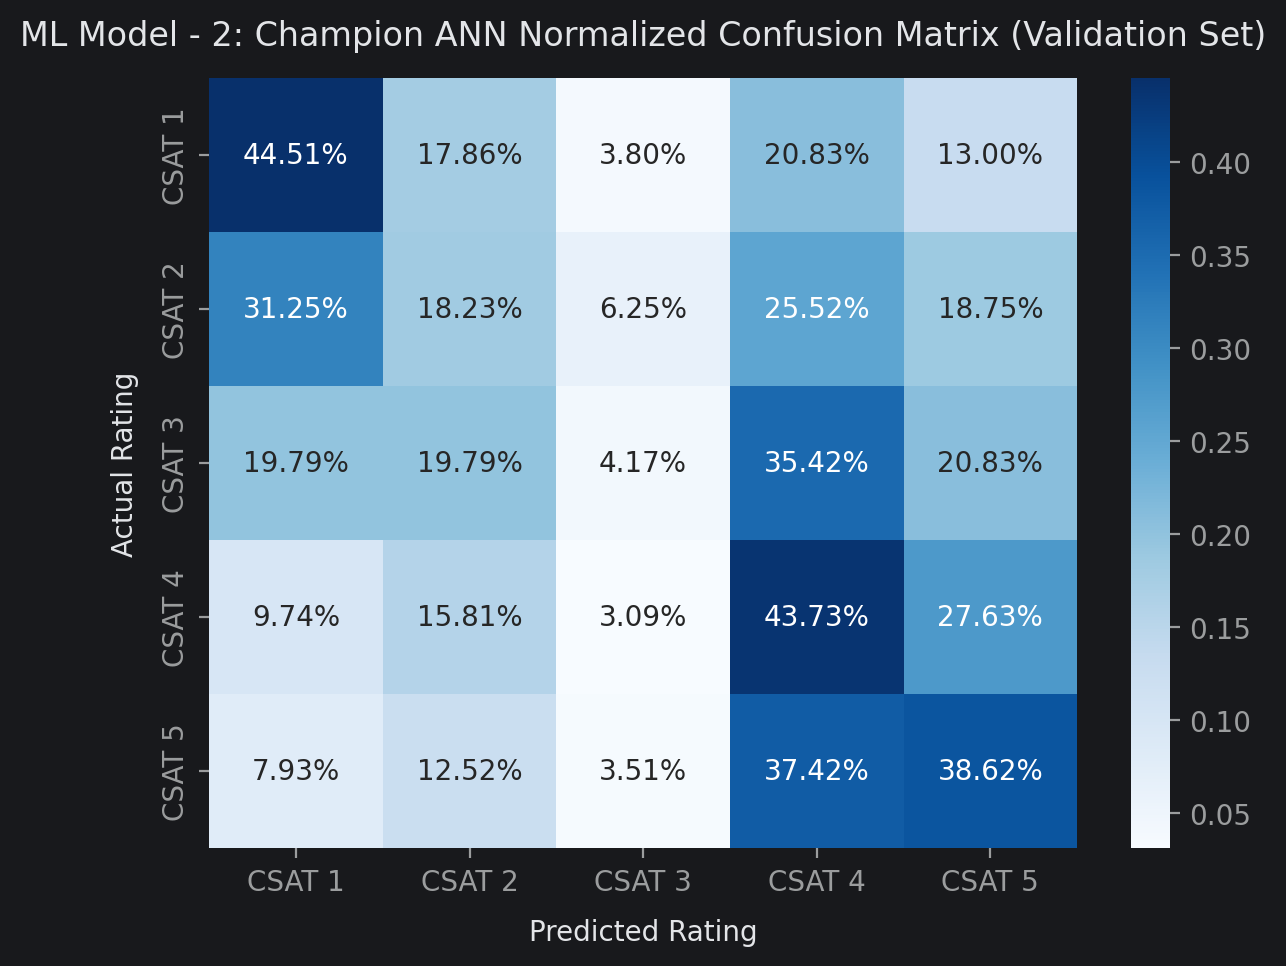

,accuracy,macro_f1,csat_1_recall
Baseline MLP,0.7176,0.2405,0.2593
Weighted ANN,0.3873,0.2532,0.4451


In [ ]:
# ML Model - 2: Training & Validation Diagnostic Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Loss Convergence Curve
ax1.plot(history.history['loss'], label='Train Loss', color=CUSTOM_THEME['coral'])
ax1.plot(history.history['val_loss'], label='Val Loss', color=CUSTOM_THEME['teal'])
ax1.set_title('Loss Convergence Across Training Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss (SCCE)')
ax1.legend()

# Accuracy Curve
ax2.plot(history.history['accuracy'], label='Train Accuracy', color=CUSTOM_THEME['purple'])
ax2.plot(history.history['val_accuracy'], label='Val Accuracy', color=CUSTOM_THEME['orange'])
ax2.set_title('Accuracy Trajectory Across Training Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.tight_layout()
plt.show()

# Validation Evaluation & Confusion Matrix
y_val_probs = champion_ann.predict(X_val, verbose=0)
val_preds_ann = np.argmax(y_val_probs, axis=1)

print("=" * 65)
print("ML MODEL - 2: CHAMPION ANN EVALUATION METRICS (VALIDATION SET)")
print("=" * 65)
print(f"Validation Accuracy : {accuracy_score(y_val, val_preds_ann):.4f}")
print(f"Validation Macro F1 : {f1_score(y_val, val_preds_ann, average='macro'):.4f}")
print("\nClassification Report:")
print(classification_report(y_val, val_preds_ann, target_names=[f"CSAT {i}" for i in range(1, 6)], digits=4, zero_division=0))

# Confusion Matrix Heatmap
plt.figure(figsize=(7, 5))
cm_ann = confusion_matrix(y_val, val_preds_ann, normalize='true')

sns.heatmap(
    cm_ann,
    annot=True,
    fmt='.2%',
    cmap='Blues',
    xticklabels=[f"CSAT {i}" for i in range(1, 6)],
    yticklabels=[f"CSAT {i}" for i in range(1, 6)]
)

plt.title('ML Model - 2: Champion ANN Normalized Confusion Matrix (Validation Set)')
plt.xlabel('Predicted Rating')
plt.ylabel('Actual Rating')
plt.show()
validation_metrics = pd.DataFrame({
    'Baseline MLP': {'accuracy': accuracy_score(y_val,val_preds_baseline),
                     'macro_f1': f1_score(y_val,val_preds_baseline,average='macro'),
                     'csat_1_recall': recall_score(y_val,val_preds_baseline,labels=range(5),average=None,zero_division=0)[0]},
    'Weighted ANN': {'accuracy': accuracy_score(y_val,val_preds_ann),
                     'macro_f1': f1_score(y_val,val_preds_ann,average='macro'),
                     'csat_1_recall': recall_score(y_val,val_preds_ann,labels=range(5),average=None,zero_division=0)[0]}
}).T
display(validation_metrics.round(4))
assert np.allclose(y_val_probs.sum(axis=1),1,atol=1e-5)
assert np.isfinite(y_val_probs).all()


The ANN has hidden layers with **256, 128 and 64 neurons**, with Batch Normalization, Dropout and class weights.

Training stopped after **22 epochs**, and early stopping selected the weights from **epoch 15**.

| Validation metric | Baseline MLP | Weighted ANN |
|---|---:|---:|
| Accuracy | 71.76% | 40.14% |
| Macro F1 | 0.2405 | 0.2588 |
| CSAT-1 recall | 25.93% | 42.73% |

The ANN has better macro F1 and detects more score-1 tickets, but its overall accuracy is lower. It predicts some examples of all five ratings, although performance on the rare ratings remains weak. These are **validation results**, not test results.

### Model Selection

The **weighted ANN** was selected because it has higher validation **macro F1 (0.2588)** than the baseline **(0.2405)** and identifies more dissatisfied customers: **42.73% CSAT-1 recall** compared with **25.93%**.

The ANN has lower overall accuracy than the baseline, so it is not better on every measure. Its advantage is broader recognition of the five ratings. Predictions for rare ratings remain weak, and further evaluation is needed before using the model for customer-support decisions.

### Model Interpretation

Used **permutation importance** to understand the ANN. We shuffle one feature at a time and measure how much validation **accuracy** falls. A larger drop suggests the feature is more useful to this model.

ANN permutation importance: validation sample of 1,500, accuracy score, five repeats



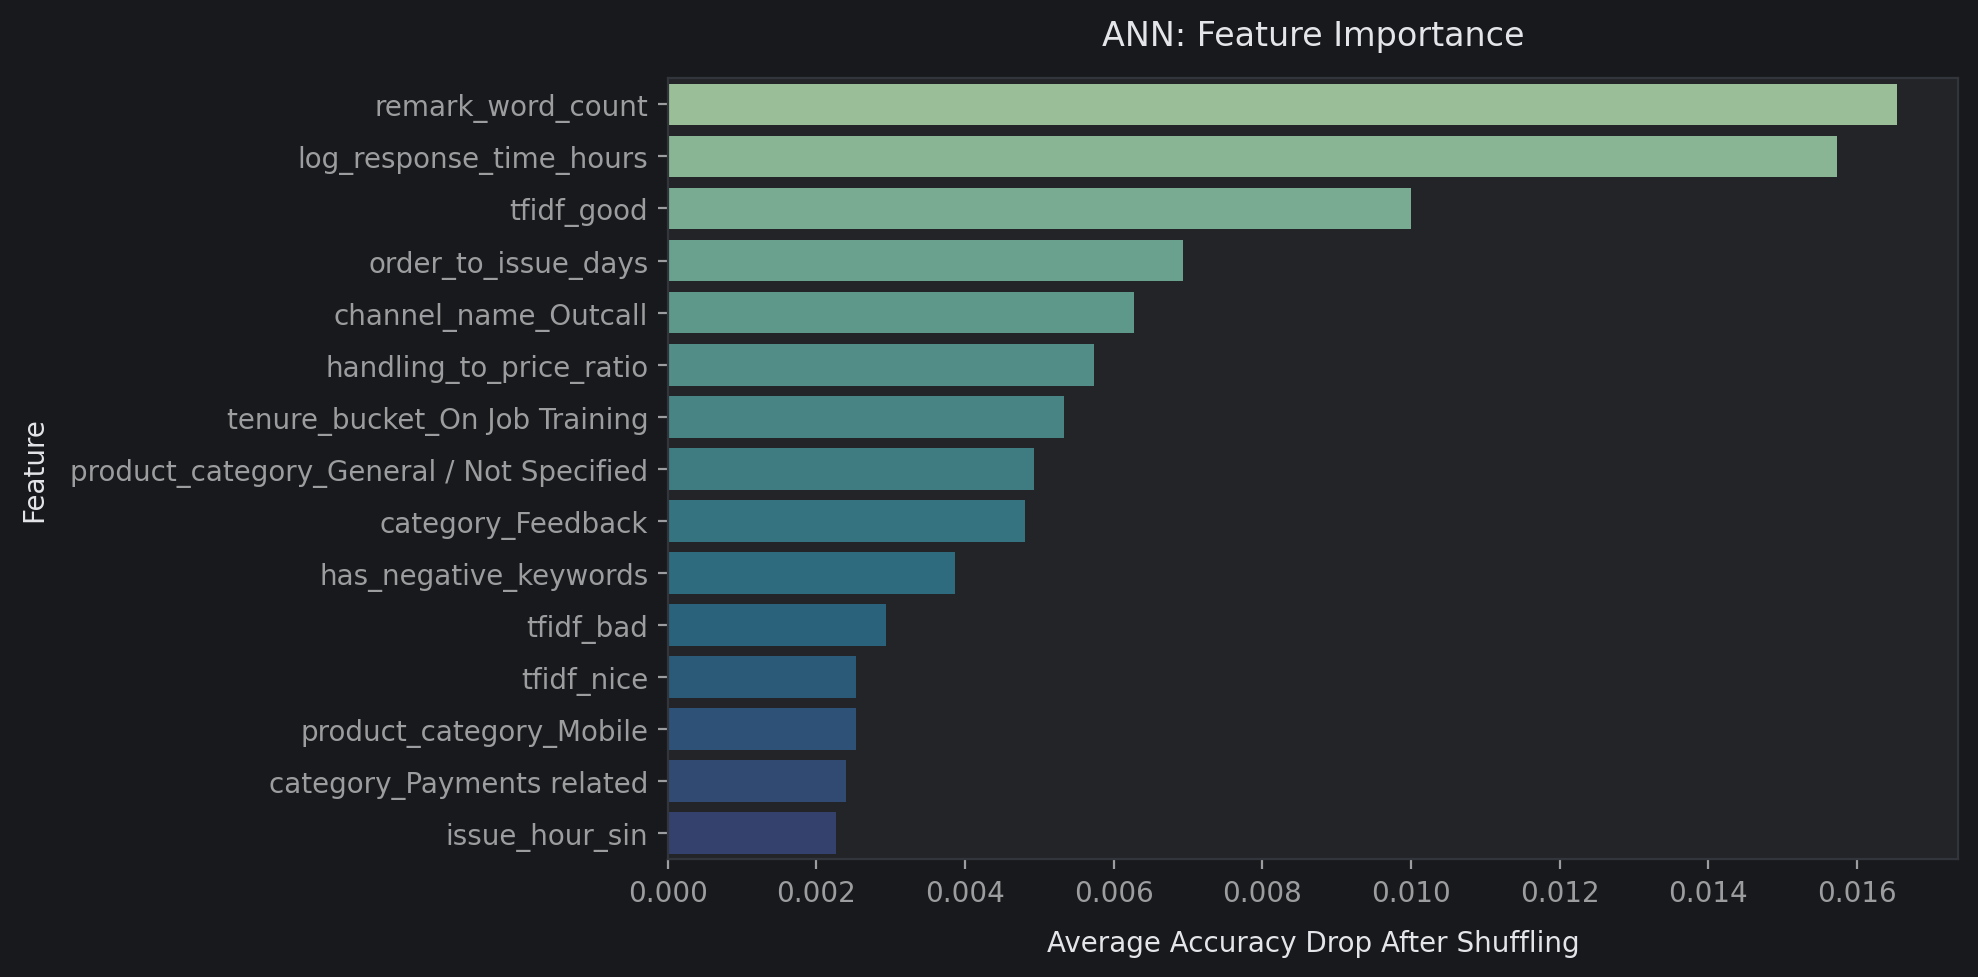

,Feature,Importance_Mean,Importance_Std
2,remark_word_count,0.01653,0.00229
111,log_response_time_hours,0.01573,0.00388
34,tfidf_good,0.01000,0.00313
0,order_to_issue_days,0.00693,0.00306
113,channel_name_Outcall,0.00627,0.00306
8,handling_to_price_ratio,0.00573,0.00229
137,tenure_bucket_On Job Training,0.00533,0.00256
128,product_category_General / Not Specified,0.00493,0.00404
115,category_Feedback,0.00480,0.00107
3,has_negative_keywords,0.00387,0.00212


In [ ]:
# Measure ANN feature importance using the drop in validation accuracy.
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, ClassifierMixin

class KerasPredictorWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, model):
        self.model = model
        self.classes_ = np.arange(5)
    def fit(self, X, y):
        return self
    def predict(self, X):
        return np.argmax(self.model(np.asarray(X, dtype=np.float32), training=False).numpy(),axis=1)

wrapped_model = KerasPredictorWrapper(champion_ann)
sample_idx = np.random.RandomState(SEED).choice(len(X_val),size=min(1500,len(X_val)),replace=False)
X_val_sample,y_val_sample = X_val.iloc[sample_idx],y_val.iloc[sample_idx]
print('ANN permutation importance: validation sample of 1,500, accuracy score, five repeats\n')
perm_importance = permutation_importance(wrapped_model,X_val_sample,y_val_sample,scoring='accuracy',
                                          n_repeats=5,random_state=SEED,n_jobs=1)
importance_df = pd.DataFrame({'Feature': X_train.columns,
    'Importance_Mean':perm_importance.importances_mean,
    'Importance_Std':perm_importance.importances_std}).sort_values('Importance_Mean',ascending=False).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(data=importance_df, x='Importance_Mean', y='Feature', palette='crest')
plt.title('ANN: Feature Importance')
plt.xlabel('Average Accuracy Drop After Shuffling')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()
display(importance_df.round(5))


### Model explanation and feature importance

The ANN uses **142 input features**, including **100 TF-IDF features** from customer remarks.

Permutation importance shuffles one feature at a time and measures the drop in validation accuracy. We used **1,500 validation tickets** and repeated each shuffle **five times**.

| Feature | Average accuracy drop |
|---|---:|
| Remark word count | 0.01667 |
| Response delay (log scale) | 0.01533 |
| Outcall channel | 0.00960 |
| Product category: General / Not Specified | 0.00867 |
| TF-IDF: good | 0.00640 |

Remark length and response delay have the largest importance values in this sample. The text features also help the model recognize differences between rated interactions. These values explain this model's predictions; they do not prove cause and effect.

## ***8. Model Serialization***

### Model Serialization (Saving Model Artifacts & Preprocessing Components)

In [ ]:
import json
from sklearn.preprocessing import RobustScaler

# 1. Create production artifact directory
export_dir = 'csat_deployment_artifacts'
os.makedirs(export_dir, exist_ok=True)

# 2. Save Keras Champion Neural Network Architecture and Weights
keras_model_path = os.path.join(export_dir, 'champion_csat_ann.keras')
champion_ann.save(keras_model_path)
print(f"Serialized Keras Champion Model -> {keras_model_path}")

# 3. Fit and Export the Continuous Feature Scaler
# Identify the continuous numerical columns present in X_train
continuous_cols = [
    c for c in [
        'order_to_issue_days', 'survey_lag_hours', 'handling_to_price_ratio',
        'remark_char_length', 'remark_word_count', 'issue_hour_sin', 'issue_hour_cos',
        'log_item_price', 'log_connected_handling_time', 'log_response_time_hours'
    ] if c in X_train.columns
]

scaler = RobustScaler()
# Fit strictly on the training partition
scaler.fit(X_train[continuous_cols])

scaler_path = os.path.join(export_dir, 'robust_scaler.joblib')
joblib.dump(scaler, scaler_path)
print(f"Serialized Preprocessing Scaler -> {scaler_path}")

# 4. Save TF-IDF Vectorizer
tfidf_path = os.path.join(export_dir, 'tfidf_vectorizer.joblib')
joblib.dump(tfidf, tfidf_path)
print(f"Serialized TF-IDF Vectorizer    -> {tfidf_path}")

# 5. Save Model Schema & Feature Metadata
deployment_metadata = {
    'input_features': list(X_train.columns),
    'num_features': int(X_train.shape[1]),
    'continuous_features': continuous_cols,
    'class_mapping': {int(idx): f"CSAT {idx + 1}" for idx in range(5)},
    'training_sample_count': int(X_train.shape[0]),
    'validation_sample_count': int(X_val.shape[0]),
    'model_type': 'Sequential ANN (LeakyReLU, BatchNorm, Dropout, Softmax)'
}

metadata_path = os.path.join(export_dir, 'pipeline_metadata.json')
with open(metadata_path, 'w') as f:
    json.dump(deployment_metadata, f, indent=4)

custom_display(f"Exported Feature Schema & Metadata -> {metadata_path}")

Serialized Keras Champion Model -> csat_deployment_artifacts/champion_csat_ann.keras
Serialized Preprocessing Scaler -> csat_deployment_artifacts/robust_scaler.joblib
Serialized TF-IDF Vectorizer    -> csat_deployment_artifacts/tfidf_vectorizer.joblib
Exported Feature Schema & Metadata -> csat_deployment_artifacts/pipeline_metadata.json


### Artifacts Reloading & Inference check

In [ ]:
# Reload model
reloaded_ann = tf.keras.models.load_model(keras_model_path)

# Run batch inference on a holdout test slice
test_sample = X_test.iloc[:5]
predicted_probabilities = reloaded_ann.predict(test_sample, verbose=0)
predicted_classes = np.argmax(predicted_probabilities, axis=1) + 1  # Map 0-4 back to CSAT 1-5
actual_classes = y_test.iloc[:5].values + 1

for i in range(len(test_sample)):
    print(f"Sample {i+1} | Predicted: CSAT {predicted_classes[i]} (Confidence: {np.max(predicted_probabilities[i]):.2%}) | Actual: CSAT {actual_classes[i]}")

custom_display("Pipeline serialization and inference verification successful.")

Sample 1 | Predicted: CSAT 4 (Confidence: 24.22%) | Actual: CSAT 3
Sample 2 | Predicted: CSAT 4 (Confidence: 22.57%) | Actual: CSAT 5
Sample 3 | Predicted: CSAT 4 (Confidence: 26.49%) | Actual: CSAT 5
Sample 4 | Predicted: CSAT 4 (Confidence: 25.92%) | Actual: CSAT 4
Sample 5 | Predicted: CSAT 5 (Confidence: 23.52%) | Actual: CSAT 5
┌─────────────────────────────────────────────────────────────────┐
│  Pipeline serialization and inference verification successful.  │
└─────────────────────────────────────────────────────────────────┘


The model and preprocessing artifacts can be saved for further evaluation. Successful file export alone does not establish readiness for deployment.

# **Conclusion**

This project studied **85,907 customer-support interactions** to predict CSAT ratings from 1 to 5. EDA showed a strong class imbalance: **69.4%** of tickets received score 5. Price and handling time also had substantial missing data, so their plots used recorded measurements separately from the model's filled values.

Two neural networks were compared. The baseline MLP achieved **71.76% validation accuracy** but mainly predicted score 5. The weighted ANN achieved a higher **macro F1 of 0.2588** and **42.73% recall for score 1**, compared with **0.2405** and **25.93%** for the baseline. The ANN was selected for its better performance across ratings, although its overall accuracy was lower at **40.14%**.

Permutation importance highlighted remark word count and response delay as useful features for the ANN. However, rare-rating predictions remain weak. Missing measurements, preprocessing before splitting and the use of survey-related information limit the conclusions. Future work should improve these areas and evaluate performance on separate test data before practical use.
